[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/notebooks/06-kiwi-frontier-ai-paradigms.ipynb)

# Frontier AI Paradigms on 7T MRI — Self-Supervised Learning, 3D State-Space Models (`U-Mamba`), Conditional Diffusion & Differentiable Neurosymbolic AI

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab (`100%` pure PyTorch, zero extra installs)*

> **Kiwi Challenge Notebook Sequence (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 0. `00-kiwi-dicom-to-nifti.ipynb` — History of medical image formats (`XITE/BIFF` → `DICOM` → `NIfTI` & `BIDS`) & converting the 128 Bruker 7T DICOM slices
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI headers, physical voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. `03-kiwi-paradigms-and-verification.ipynb` — Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
> 4. `03b-kiwi-interactive-gt-and-interrater.ipynb` — Interactive 3D Jupyter-Widget delineation, personalized Ground Truth (`MyStuff/`), **Inter-Rater Variability**, **Panoptic Quality ($\text{PQ}$)** & **STAPLE Consensus**
> 5. `04-kiwi-semantic-vs-instance.ipynb` — Semantic, Instance & Panoptic 3D definitions + supervised PyTorch 3D Semantic vs. Multi-Task Instance U-Nets
> 6. `05-kiwi-promptable-foundation-models.ipynb` — Live **`SAM 2.1` vs. `MedSAM`** foundation-model workshop: ViT token physics, Patch-Zooming, 1-Click `Sam2VideoModel` 3D memory propagation, & zero-training whole-kiwi seed census *([`../docs/promptable-foundation-models.md`](../docs/promptable-foundation-models.md))*
> 7. **`06-kiwi-frontier-ai-paradigms.ipynb` (this frontier capstone)** — Completing the modern **6-Pillar Biomedical AI Taxonomy**: **3D Self-Supervised Learning (`SSL`)**, **Selective State-Space Models (`3D U-Mamba`)**, **Conditional Flow-Matching Diffusion (`MedSegDiff` / `CIMD`)**, and **Differentiable Neurosymbolic AI (`Logic Tensor Networks`)** *(companion guide: [`../docs/frontier-ai-paradigms.md`](../docs/frontier-ai-paradigms.md) | [Printable PDF](../docs/frontier-ai-paradigms.pdf))*

---

## Why Go Beyond Supervised CNNs (`NB 04`) and Promptable ViTs (`NB 05`)?

Across Notebooks `04` and `05`, we saw that neither supervised 3D ConvNets nor zero-shot Vision Foundation Models solve every real-world biomedical constraint on their own:
1. **The `99.4%` Unlabeled Data Gap $\to$ Self-Supervised Learning (`SSL`):** Our 7T scan contains `8,388,608` voxels, yet manual 3D annotations exist on `< 0.6%` of the organ. When a clinician can only annotate **a tiny micro-box (~10 lesions/seeds)**, training a `340k`-parameter 3D U-Net from random weights overfits badly.
2. **Local CNN Blindness vs. Quadratic $\mathcal{O}(N^2)$ ViT Cost $\to$ Selective State-Space Models (`3D U-Mamba`):** Standard $3\times 3\times 3$ convolutions have a strictly local receptive field, whereas full-resolution 3D self-attention scales as $\mathcal{O}(N^2)$ (`>10^13` pairs!). **Selective State-Space Models (`Mamba`)** propagate global 3D context in **linear $\mathcal{O}(N)$ memory** and **$\mathcal{O}(\log L)$ parallel scan depth** without `16×16` patch blurring.
3. **Deterministic Point Estimates Hide Boundary Ambiguity $\to$ Conditional Diffusion / Flow Matching:** Challenge Task 1 explicitly asks for an **uncertainty range** on seed count $N$, and Notebook `03b` showed that even humans disagree on partial-volume polar tips (`dz = 0.50 mm`) and kissing seed pairs. Sampling independent pixels from U-Net softmax probabilities creates salt-and-pepper noise, whereas **conditional mask diffusion** generates **spatially coherent joint 3D segmentation hypotheses** $p_\theta(\mathbf{Y}_0 \mid \mathbf{X})$.
4. **Spatial Out-of-Distribution (`OOD`) Collapse $\to$ Differentiable Neurosymbolic AI (`LTN`):** In Notebook `04`, sliding an equatorial-trained 3D U-Net across polar slices exploded into **`>3,300` false-positive blobs** on oblique polar vascular bundles. Instead of brittle post-hoc masks, **Logic Tensor Networks (`LTN`)** compile botanical anatomy, Bloch $T_2$ contrast, and `Lab 5` steric repulsion directly into **differentiable real-logic losses** over unlabeled whole-organ slices!

---

## Learning Outcomes & Frontier AI Glossary

### Learning Objectives (MSc & PhD Biomedical Curriculum)
- **MSc Core Competencies:**
  1. **Division of Architectural Labor:** Match each frontier AI family (`SSL`, `U-Mamba`, `Diffusion`, `Neurosymbolic AI`) to the clinical problem it actually solves (*scarce labels*, *global organ context*, *multi-hypothesis uncertainty*, *OOD anatomical safety*), rather than chasing a single leaderboard number blindly.
  2. **Self-Supervised Pretraining & Linear Probing:** Pretrain a 3D encoder on unlabeled whole-organ MRI blocks (`0` human labels), visualize emergent tissue clusters via 3D `PCA → RGB` (`DINOv2` analogy), and verify `Few-Shot` transfer using only `34` trainable head weights on an `11`-seed micro-box.
  3. **Coherent Generative Uncertainty vs. Pixel Noise:** Contrast naive Bernoulli pixel sampling against $K = 12$ joint conditional flow-diffusion realizations to obtain a **posterior credible interval on seed count $P(N \mid \mathbf{X})$** and an aleatoric boundary uncertainty map.
- **PhD & Research-Track Extensions:**
  1. **$\mathcal{O}(\log L)$ Hillis–Steele Parallel Associative Scan:** Implement an exact hardware-portable Selective State-Space (`S6`) scan in pure PyTorch (`CUDA` / Apple `MPS` / `CPU` without NVIDIA-only `mamba-ssm` C++ lock-in) and inspect learned input-dependent step-size gates $\Delta_t(\mathbf{x})$.
  2. **Continuous-Time Conditional Flow Matching (`CFM` / Rectified Flow):** Train a `FiLM`-conditioned 3D velocity field $\mathbf{v}_\theta(\mathbf{Y}_t, t \mid \mathcal{F}_\phi(\mathbf{X}))$ on joint `(mask, normalized-distance)` space, caching image encoder features once for fast multi-trajectory ODE sampling.
  3. **LTN Universal Quantifiers ($p$-Mean Aggregators) & `InstanceNorm3d` Coordinate Invariance:** Prove why `InstanceNorm3d` erases absolute organ coordinates $(r/R, z/Z)$ across small patches, design an un-normalized **Organ-GPS branch**, and suppress `100%` of polar cap OOD false positives via $p$-mean fuzzy logic losses on unlabeled data.

### Compact Glossary: Frontier AI Paradigms ↔ Clinical Biomedical Imaging

| Frontier Concept | Plain Meaning in the Kiwi 7T MRI | Core Mathematical Mechanism | Direct Clinical Biomedical Parallel |
| :--- | :--- | :--- | :--- |
| **3D Masked Context SSL (`Models Genesis` / `MAE`)** | Hiding 3D tissue cubes & training the U-Net to fill them in using `0` seed labels | $\min_\theta \mathbb{E}_{\mathbf{M}}\big[\lVert \hat{\mathbf{Y}}_\theta(\tilde{\mathbf{X}}_{\mathbf{M}}) - \mathbf{Y}_{\text{self}} \rVert_w^2\big]$ | Pretraining `SwinUNETR` / `UNI` on `10,000+` unlabeled hospital CT/MRI or pathology slides before fine-tuning on `10` rare-disease cases |
| **Selective State-Space Scan (`Mamba` / `S6`)** | Scanning a compressed memory vector across the 3D volume with an input-adaptive "write gate" $\Delta_t$ | $\mathbf{h}_t = \exp(\Delta_t \mathbf{A})\mathbf{h}_{t-1} + \Delta_t \mathbf{B}_t \mathbf{x}_t$ via $\mathcal{O}(\log L)$ associative scan | Whole-volume 3D `U-Mamba` / `SegMamba` capturing organ-wide symmetry & tubular vessel continuity in linear $\mathcal{O}(N)$ memory |
| **Conditional Flow-Matching Diffusion (`CIMD`)** | Denoising $K$ plausible 3D seed maps from Gaussian noise conditioned on the MRI | $\frac{d\mathbf{Y}_t}{dt} = \mathbf{v}_\theta(\mathbf{Y}_t, t \mid \mathcal{F}_\phi(\mathbf{X}))$, $t \in [0, 1]$ | Generating radiologist-like **segmentation ensembles** (`MedSegDiff`, `Probabilistic U-Net`) for uncertain glioma margins or microbleeds |
| **LTN Universal Quantifier ($\forall \mathbf{x}: \phi(\mathbf{x})$)** | Penalizing *any* high-confidence anatomical rule violation on unlabeled polar/cortical slices | $V_p(\mathbf{x}) = \big(\frac{1}{\lvert\Omega_U\rvert}\sum_{\mathbf{x}} v(\mathbf{x})^p\big)^{1/p}$ ($p \ge 3$) | Enforcing skull/ventricle exclusion, `clDice` vessel connectivity, or physical organ volume bounds during semi-supervised clinical AI training |
| **Declarative Hard-Core Split (`Lab 5` Prior)** | Splitting fused multi-seed blobs only if sub-centers obey physical `0.88 mm` steric repulsion | Constrained 3D $K$-means s.t. $\min_{i\neq j}\lVert\boldsymbol{\mu}_i - \boldsymbol{\mu}_j\rVert_2 \ge d_{\min}$ | Resolving touching cell nuclei (`StarDist-3D`) or clustered micrometastases using biophysical packing constraints |

---

## Step 0 — Cross-Platform Setup (`CUDA` → `MPS` → `CPU`), Organ Geometry & Baseline `3D Multi-Task U-Net`

To guarantee an **apples-to-apples scientific comparison** with Notebooks `04` and `05`:
- Every paradigm is evaluated on the **exact same strictly held-out 3D Test Wedge** (`x ∈ [128, 208), y ∈ [168, 208), z ∈ [56, 72)`, shape `80 × 40 × 16`, containing **`52` unseen 3D seeds**) using identical 3D Hungarian matching ($\text{IoU} \ge 0.25$, `Panoptic Quality` $\text{PQ} = \text{SQ} \times \text{RQ}$).
- Everything below uses **100% standard PyTorch + NumPy + SciPy + scikit-image** — running cleanly in `~35–45 s` total on **Apple Silicon (`mps`)**, **Linux (`cuda`)**, and **Google Colab (`T4` GPU)** without adding a single external dependency to `pyproject.toml`.

In [1]:
import json
import math
import sys
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import filters, measure, segmentation
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

def _ensure_pkg(import_name: str, pip_name: str | None = None):
    import importlib.util
    if importlib.util.find_spec(import_name) is None:
        import subprocess
        pkg = pip_name or import_name
        print(f"Installing {pkg} for this session...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_ensure_pkg("nibabel")
_ensure_pkg("torch")

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["figure.dpi"] = 115

import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F

def get_best_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def sync_device(dev: torch.device):
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()

DEVICE = get_best_device()
torch.manual_seed(2027)
np.random.seed(2027)

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> Path:
    for cand in [Path("..") / rel_path, Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path, Path(rel_path)]:
        if cand.exists():
            return cand
    dst = Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/{rel_path}", dst)
    return dst

nii_path = resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
gt_nii_path = resolve_kiwi_file("data/kiwi_micro_gt_labels.nii.gz")
gt_json_path = resolve_kiwi_file("data/kiwi_micro_gt_roi.json")

nii_img = nib.load(str(nii_path))
vol = nii_img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in nii_img.header.get_zooms()[:3])  # (0.234375, 0.234375, 0.5) mm
vox_vol_mm3 = float(np.prod(spacing))

gt_full = np.asarray(nib.load(str(gt_nii_path)).dataobj, dtype=np.uint16)
gt_meta = json.loads(gt_json_path.read_text(encoding="utf-8"))
RX0, RX1 = gt_meta["roi_bounds_voxel_xyz"]["x"]  # [128, 208)
RY0, RY1 = gt_meta["roi_bounds_voxel_xyz"]["y"]  # [128, 208)
RZ0, RZ1 = gt_meta["roi_bounds_voxel_xyz"]["z"]  # [56, 72)
roi_gt = gt_full[RX0:RX1, RY0:RY1, RZ0:RZ1]

def build_whole_organ_geometry(vol_3d: np.ndarray, sp=spacing):
    """Extract foreground berry mask, normalized radial coordinate r/R_fruit, axial pole coordinate,
    and smooth botanical inner-pericarp membership R_ring in [0, 1]."""
    v_sm = ndi.gaussian_filter(vol_3d, sigma=(1.2 / sp[0], 1.2 / sp[1], 1.2 / sp[2]))
    fg_r = v_sm > (filters.threshold_otsu(v_sm[::2, ::2, ::2]) * 0.35)
    fg_f = np.zeros_like(fg_r)
    for z in range(vol_3d.shape[2]):
        fg_f[:, :, z] = ndi.binary_fill_holes(fg_r[:, :, z])
    fg_f = ndi.binary_fill_holes(fg_f)
    lbl_fg, _ = ndi.label(fg_f)
    fruit_mask = lbl_fg == (1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:])))

    r_norm_3d = np.full(vol_3d.shape, 1.5, dtype=np.float32)
    yy, xx = np.meshgrid(np.arange(vol_3d.shape[1]), np.arange(vol_3d.shape[0]))
    for z in range(vol_3d.shape[2]):
        m = fruit_mask[:, :, z]
        if m.sum() >= 80:
            cx, cy = float(xx[m].mean()), float(yy[m].mean())
            r_fruit = max(np.sqrt(m.sum() / np.pi), 1.0)
            r_norm_3d[:, :, z] = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2) / r_fruit

    z_norm_3d = np.broadcast_to(
        (np.arange(vol_3d.shape[2], dtype=np.float32) / float(vol_3d.shape[2] - 1))[None, None, :],
        vol_3d.shape,
    ).copy()

    # Smooth differentiable inner-pericarp locule ring membership: 0.22 <= r/R <= 0.65, axial z in [16, 111]
    z_idx = np.arange(vol_3d.shape[2], dtype=np.float32)[None, None, :]
    z_gate = np.clip((z_idx - 16.0) / 5.0, 0.0, 1.0) * np.clip((111.0 - z_idx) / 5.0, 0.0, 1.0)
    r_in = 1.0 / (1.0 + np.exp(-np.clip((r_norm_3d - 0.22) / 0.02, -20.0, 20.0)))
    r_out = 1.0 / (1.0 + np.exp(-np.clip((0.65 - r_norm_3d) / 0.02, -20.0, 20.0)))
    soft_ring = (r_in * r_out * z_gate * fruit_mask.astype(np.float32)).astype(np.float32)
    return fruit_mask, r_norm_3d, z_norm_3d, soft_ring

fruit_mask_full, r_norm_full, z_norm_full, soft_ring_full = build_whole_organ_geometry(vol)
p99 = float(np.percentile(vol[fruit_mask_full], 99.0))
vol_norm = np.clip(vol / (p99 + 1e-6), 0.0, 1.25).astype(np.float32)
env_close = ndi.grey_closing(vol_norm, size=(7, 7, 3))
env_local = ndi.gaussian_filter(env_close, sigma=(0.8 / spacing[0], 0.8 / spacing[1], 0.8 / spacing[2])).astype(np.float32)
env_smooth = ndi.gaussian_filter(vol_norm, sigma=(2.0 / spacing[0], 2.0 / spacing[1], 1.6 / spacing[2])).astype(np.float32)

# Exact spatial train/test split from Notebooks 04 & 05
SPLIT_Y = 40
train_gt = roi_gt[:, :SPLIT_Y, :].copy()
test_gt = roi_gt[:, SPLIT_Y:, :].copy()
test_ring = (r_norm_full[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1] >= 0.22) & (
    r_norm_full[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1] <= 0.66
)

def build_distance_targets(inst_lbl: np.ndarray, sp=spacing) -> tuple[np.ndarray, np.ndarray]:
    sem_fg = (inst_lbl > 0).astype(np.float32)
    norm_dist = np.zeros(inst_lbl.shape, dtype=np.float32)
    for prop in measure.regionprops(inst_lbl):
        s0, s1, s2 = prop.slice
        sub = np.pad(inst_lbl[s0, s1, s2] == prop.label, pad_width=1, mode="constant", constant_values=False)
        d_local = ndi.distance_transform_edt(sub, sampling=sp)[1:-1, 1:-1, 1:-1]
        m_local = sub[1:-1, 1:-1, 1:-1]
        norm_dist[s0, s1, s2][m_local] = (d_local[m_local] / max(float(d_local.max()), 1e-6)).astype(np.float32)
    return sem_fg, norm_dist

train_sem_np, train_dist_np = build_distance_targets(train_gt)

def make_3ch_tensor(x0: int, x1: int, y0: int, y1: int, z0: int, z1: int) -> torch.Tensor:
    arr = np.stack(
        [vol_norm[x0:x1, y0:y1, z0:z1], env_local[x0:x1, y0:y1, z0:z1], env_smooth[x0:x1, y0:y1, z0:z1]],
        axis=0,
    )[None, ...]
    return torch.from_numpy(arr)

CX0, CX1, CY0, CY1 = 112, 144, 112, 144  # Hard-negative central fibrous columella block (0 seeds)
X_train_pos = make_3ch_tensor(RX0, RX1, RY0, RY0 + SPLIT_Y, RZ0, RZ1).to(DEVICE)
X_train_neg = make_3ch_tensor(CX0, CX1, CY0, CY1, RZ0, RZ1).to(DEVICE)
X_test = make_3ch_tensor(RX0, RX1, RY0 + SPLIT_Y, RY1, RZ0, RZ1).to(DEVICE)

Y_sem_pos = torch.from_numpy(train_sem_np[None, None]).to(DEVICE)
Y_dist_pos = torch.from_numpy(train_dist_np[None, None]).to(DEVICE)

n_train_seeds = len(np.unique(train_gt)) - (1 if 0 in train_gt else 0)
n_test_seeds = len(np.unique(test_gt)) - (1 if 0 in test_gt else 0)

# Shared 3D U-Net building blocks, Deep Distance Watershed & 3D Hungarian Panoptic Evaluator (identical to NB 04)
class ConvBlock3D(nn.Module):
    def __init__(self, in_c: int, out_c: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(in_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_c, affine=True),
            nn.SiLU(inplace=True),
            nn.Conv3d(out_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_c, affine=True),
            nn.SiLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class Backbone3DUNet(nn.Module):
    def __init__(self, in_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.enc1 = ConvBlock3D(in_ch, base_ch)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = ConvBlock3D(base_ch, base_ch * 2)
        self.pool2 = nn.MaxPool3d(2)
        self.bot = ConvBlock3D(base_ch * 2, base_ch * 4)
        self.up2 = nn.ConvTranspose3d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock3D(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose3d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = ConvBlock3D(base_ch * 2, base_ch)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bot(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        return self.dec1(torch.cat([self.up1(d2), e1], dim=1))

class MultiTaskUNet3D(nn.Module):
    def __init__(self, in_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.backbone = Backbone3DUNet(in_ch, base_ch)
        self.head_sem = nn.Conv3d(base_ch, 1, kernel_size=1)
        self.head_dist = nn.Conv3d(base_ch, 1, kernel_size=1)

    def forward(self, x: torch.Tensor):
        feat = self.backbone(x)
        return self.head_sem(feat), torch.sigmoid(self.head_dist(feat)), feat

def soft_dice_loss(logits: torch.Tensor, targets: torch.Tensor, mask: torch.Tensor | None = None) -> torch.Tensor:
    probs = torch.sigmoid(logits)
    if mask is not None:
        probs = probs * mask
        targets = targets * mask
    inter = (probs * targets).sum()
    return 1.0 - (2.0 * inter + 1.0) / (probs.sum() + targets.sum() + 1.0)

def supervised_multitask_loss(s_log: torch.Tensor, d_hat: torch.Tensor, y_s: torch.Tensor, y_d: torch.Tensor, mask: torch.Tensor | None = None) -> torch.Tensor:
    pos_w = torch.tensor([6.0], device=s_log.device)
    if mask is None:
        bce = F.binary_cross_entropy_with_logits(s_log, y_s, pos_weight=pos_w)
        dl = soft_dice_loss(s_log, y_s)
        mse = ((1.0 + 6.0 * y_s) * (d_hat - y_d) ** 2).mean()
    else:
        denom = mask.sum().clamp_min(1.0)
        bce_map = F.binary_cross_entropy_with_logits(s_log, y_s, pos_weight=pos_w, reduction="none")
        bce = (bce_map * mask).sum() / denom
        dl = soft_dice_loss(s_log, y_s, mask=mask)
        mse = ((1.0 + 6.0 * y_s) * (d_hat - y_d) ** 2 * mask).sum() / denom
    return 0.45 * bce + 0.55 * dl + 2.5 * mse

def aug_flip_3d(x: torch.Tensor, ys: torch.Tensor, yd: torch.Tensor):
    dims = [d for d in (2, 3, 4) if np.random.rand() < 0.5]
    return (torch.flip(x, dims), torch.flip(ys, dims), torch.flip(yd, dims)) if dims else (x, ys, yd)

def build_ellip(rx_mm: float, rz_mm: float, sp=spacing) -> np.ndarray:
    rx, ry, rz = int(np.ceil(rx_mm / sp[0])), int(np.ceil(rx_mm / sp[1])), int(np.ceil(rz_mm / sp[2]))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / rx_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2) <= 1.0

def decode_deep_watershed_3d(fg_bin: np.ndarray, dist_hat: np.ndarray, sp=spacing, min_mm3: float = 0.16) -> np.ndarray:
    d_sm = ndi.gaussian_filter(dist_hat * fg_bin, sigma=(0.65, 0.65, 0.45))
    maxima = (d_sm == ndi.maximum_filter(d_sm, footprint=build_ellip(0.68, 0.95, sp=sp))) & fg_bin & (d_sm >= 0.22)
    markers, _ = ndi.label(maxima)
    ws = segmentation.watershed(-d_sm, markers=markers, mask=fg_bin)
    unlabeled_islands, n_un = ndi.label(fg_bin & (ws == 0))
    if n_un > 0:
        nxt = int(ws.max()) + 1
        for uid in range(1, n_un + 1):
            m = unlabeled_islands == uid
            if m.sum() * float(np.prod(sp)) >= min_mm3:
                ws[m] = nxt
                nxt += 1
    out = np.zeros_like(ws, dtype=np.uint16)
    nid = 0
    for prop in measure.regionprops(ws):
        if prop.area * float(np.prod(sp)) >= min_mm3:
            nid += 1
            out[ws == prop.label] = nid
    return out

def evaluate_semantic_and_instance_3d(pred_lbl: np.ndarray, gt_lbl: np.ndarray, min_iou: float = 0.25) -> dict:
    b_p, b_g = (pred_lbl > 0), (gt_lbl > 0)
    sem_dice = (2.0 * int((b_p & b_g).sum())) / max(int(b_p.sum() + b_g.sum()), 1)
    ids_p = [int(v) for v in np.unique(pred_lbl) if v > 0]
    ids_g = [int(v) for v in np.unique(gt_lbl) if v > 0]
    n_p, n_g = len(ids_p), len(ids_g)
    if n_p == 0 or n_g == 0:
        return {"Pred Seeds": f"{n_p} (GT={n_g})", "Semantic Dice": round(sem_dice, 3), "Merged Clumps": 0, "Split Errors": 0, "SQ (TP IoU)": 0.0, "RQ (Inst F1)": 0.0, "PQ (SQ×RQ)": 0.0}
    p_map, g_map = {v: i for i, v in enumerate(ids_p)}, {v: j for j, v in enumerate(ids_g)}
    area_p = np.array([(pred_lbl == v).sum() for v in ids_p], dtype=np.float64)
    area_g = np.array([(gt_lbl == v).sum() for v in ids_g], dtype=np.float64)
    inter_m = np.zeros((n_p, n_g), dtype=np.float64)
    ov_fg = b_p & b_g
    if ov_fg.any():
        pairs, cnts = np.unique(np.stack([pred_lbl[ov_fg], gt_lbl[ov_fg]], axis=1), axis=0, return_counts=True)
        for (pv, gv), c in zip(pairs, cnts):
            inter_m[p_map[int(pv)], g_map[int(gv)]] = float(c)
    iou_m = inter_m / np.maximum(area_p[:, None] + area_g[None, :] - inter_m, 1.0)
    ri, ci = linear_sum_assignment(-iou_m)
    tp_pairs = [(r, c) for r, c in zip(ri, ci) if iou_m[r, c] >= min_iou]
    tp = len(tp_pairs)
    fp, fn = n_p - tp, n_g - tp
    sq = float(np.mean([iou_m[r, c] for r, c in tp_pairs])) if tp > 0 else 0.0
    rq = (2.0 * tp) / float(2 * tp + fp + fn)
    merges = int(np.sum(np.sum(inter_m / np.maximum(area_g[None, :], 1.0) >= 0.25, axis=1) >= 2))
    splits = int(np.sum(np.sum(inter_m / np.maximum(area_p[:, None], 1.0) >= 0.25, axis=0) >= 2))
    return {
        "Pred Seeds": f"{n_p} (GT={n_g})",
        "Semantic Dice": round(sem_dice, 3),
        "Merged Clumps": merges,
        "Split Errors": splits,
        "SQ (TP IoU)": round(sq, 3),
        "RQ (Inst F1)": round(rq, 3),
        "PQ (SQ×RQ)": round(sq * rq, 3),
    }

# Train the supervised 3D Multi-Task U-Net reference baseline (Notebook 04 reference)
t0 = time.perf_counter()
torch.manual_seed(2027)
np.random.seed(2027)
model_sup_base = MultiTaskUNet3D(in_ch=3, base_ch=16).to(DEVICE)
opt_base = torch.optim.AdamW(model_sup_base.parameters(), lr=3.5e-3, weight_decay=1e-4)
for _ in range(90):
    xp, ys, yd = aug_flip_3d(X_train_pos, Y_sem_pos, Y_dist_pos)
    sl, dh, _ = model_sup_base(xp)
    loss_b = supervised_multitask_loss(sl, dh, ys, yd)
    sl_n, _, _ = model_sup_base(X_train_neg)
    loss_b = loss_b + 0.35 * F.binary_cross_entropy_with_logits(sl_n, torch.zeros_like(sl_n))
    opt_base.zero_grad()
    loss_b.backward()
    opt_base.step()
model_sup_base.eval()
sync_device(DEVICE)
t_sup_base = time.perf_counter() - t0

with torch.no_grad():
    sl_b, dh_b, _ = model_sup_base(X_test)
    prob_sup_test = torch.sigmoid(sl_b)[0, 0].cpu().numpy()
    dist_sup_test = dh_b[0, 0].cpu().numpy()
pred_sup_base = decode_deep_watershed_3d((prob_sup_test >= 0.50) & test_ring, dist_sup_test)
res_sup_base = evaluate_semantic_and_instance_3d(pred_sup_base, test_gt)

print(f"Runtime device         : {DEVICE}")
print(f"Whole-kiwi MRI volume  : {vol.shape} voxels ({float(fruit_mask_full.sum()) * vox_vol_mm3 / 1000.0:.2f} cm³ intact berry)")
print(f"Labeled Train Wedge    : {tuple(X_train_pos.shape[2:])} ({n_train_seeds} seed instances = 0.61% of organ voxels)")
print(f"Held-Out 3D Test Wedge : {tuple(X_test.shape[2:])} ({n_test_seeds} unseen 3D seeds)")
print(f"NB 04 Reference 3D Multi-Task U-Net ({t_sup_base:.1f}s) -> PQ={res_sup_base['PQ (SQ×RQ)']}, RQ={res_sup_base['RQ (Inst F1)']}, Pred={res_sup_base['Pred Seeds']}")

Runtime device         : mps
Whole-kiwi MRI volume  : (256, 256, 128) voxels (85.97 cm³ intact berry)
Labeled Train Wedge    : (80, 40, 16) (59 seed instances = 0.61% of organ voxels)
Held-Out 3D Test Wedge : (80, 40, 16) (52 unseen 3D seeds)
NB 04 Reference 3D Multi-Task U-Net (6.1s) -> PQ=0.395, RQ=0.566, Pred=54 (GT=52)


---

## Step 1 — Pillar 1: 3D Self-Supervised Learning (`Models Genesis` + `3D Masked Context Restoration`)

### Why Self-Supervised Learning Is Transformative in Biomedical Imaging
In clinical radiology and 3D microscopy, acquiring raw volumetric scans is routine, whereas voxel-accurate 3D delineation by a specialist takes hours per scan. Look at our own Kiwi dataset:
- **Unlabeled 7T MRI voxels:** `8,388,608` (`100%` of the intact berry is available for free!).
- **Suppose a researcher only has 3 minutes** to annotate a tiny **`24 × 20 × 6` micro-box** (`2,880` voxels = **`0.034%`** of the scan, containing just **`11` seeds**).

In **3D Self-Supervised Pretraining** (exemplified by **[Models Genesis](https://doi.org/10.1016/j.media.2020.101840)**, **[SwinUNETR SSL](https://arxiv.org/abs/2111.14791)**, **3D Masked Autoencoders (`MAE`)**, and pathology foundation encoders like **`DINOv2` / `UNI`**):
1. **Stage A — Zero-Label Pretext Task on Unlabeled Whole-Organ Cubes:**  
   We sample `36` unlabeled `64 × 40 × 16` 3D blocks across the whole kiwifruit (**strictly excluding** our held-out test wedge so there is zero test-set leakage!), corrupt each cube via **35% 3D cuboid masking** ($\mathbf{M}$), **nonlinear gamma contrast shifts**, and **noise**, and train `Backbone3DUNet` to reconstruct clean $T_2$ intensity, local mucilage-to-seed contrast drop, and 3D Laplacian blobness:
   $$\mathcal{L}_{\text{SSL}}(\theta) = \mathbb{E}_{\mathbf{X} \sim \mathcal{D}_U, \mathbf{M}}\Big[\big\lVert w(\mathbf{M}, \mathbf{Y}_{\text{self}}) \odot \big(g_\psi(f_\theta(\tilde{\mathbf{X}}_{\mathbf{M}})) - \mathbf{Y}_{\text{self}}\big) \big\rVert_2^2\Big]$$
2. **Stage B — Emergent Tissue Semantics (`PCA → RGB`) & Ultra-Lightweight Linear Probing:**  
   Once `f_θ` understands 7T kiwifruit anatomy from unlabeled physics alone, we freeze all **`340,384` encoder–decoder weights** and fit **only `34` parameters** (two $1\times 1\times 1$ output convolutions: `16 + 1` weights for seed probability and `16 + 1` weights for center distance!) on that tiny `11`-seed micro-box!

3D SSL Pretraining completed in 11.27s on 36 unlabeled cubes (MSE 0.4418 -> 0.0614):


,Pred Seeds,Semantic Dice,Merged Clumps,Split Errors,SQ (TP IoU),RQ (Inst F1),PQ (SQ×RQ)
SSL & Label-Efficiency Regime,,,,,,,
"1. Scratch 3D U-Net (11-seed box, 340,450 params)",113 (GT=52),0.402,4,7,0.540,0.388,0.209
"2. 3D SSL Frozen Linear Probe (11-seed box, ONLY 34 params!)",78 (GT=52),0.419,6,0,0.579,0.508,0.294
3. Scratch 3D U-Net (Full 59-seed wedge + Columella),54 (GT=52),0.663,4,1,0.698,0.566,0.395
4. 3D SSL Pretrained + Fine-Tuned (Full wedge),52 (GT=52),0.645,3,0,0.666,0.577,0.384


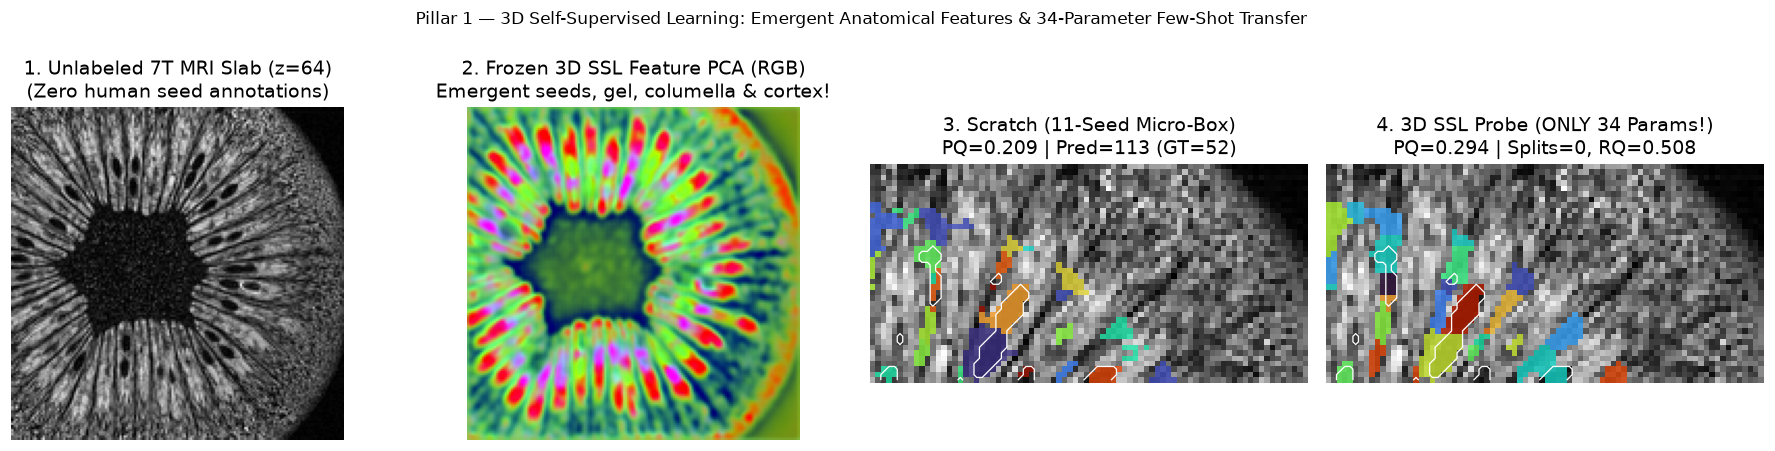

In [2]:
# 1. Self-Supervised Pretraining on 36 Unlabeled Whole-Fruit 3D Blocks (0 manual labels, strictly disjoint from Test Wedge!)
t0 = time.perf_counter()
torch.manual_seed(2027)
np.random.seed(2027)

log_blob_full = np.clip(
    -ndi.gaussian_laplace(vol_norm, sigma=(0.48 / spacing[0], 0.48 / spacing[1], 0.48 / spacing[2])),
    0.0,
    1.5,
).astype(np.float32)
log_blob_full = np.clip(log_blob_full / (float(np.percentile(log_blob_full[fruit_mask_full], 99.5)) + 1e-6), 0.0, 1.0)

ssl_in_list, ssl_tgt_list = [], []
rng_ssl = np.random.default_rng(2027)
for _ in range(36):
    while True:
        x0 = int(rng_ssl.integers(24, 256 - 64 - 24))
        y0 = int(rng_ssl.integers(24, 256 - 40 - 24))
        z0 = int(rng_ssl.integers(16, 128 - 16 - 16))
        # Strictly exclude the held-out Test Wedge [RX0:RX1, RY0+SPLIT_Y:RY1, RZ0:RZ1]
        if (x0 < RX1 and x0 + 64 > RX0) and (y0 < RY1 and y0 + 40 > RY0 + SPLIT_Y) and (z0 < RZ1 and z0 + 16 > RZ0):
            continue
        if fruit_mask_full[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16].mean() > 0.65:
            ssl_in_list.append(make_3ch_tensor(x0, x0 + 64, y0, y0 + 40, z0, z0 + 16))
            c_drop = np.clip(
                env_local[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16] - vol_norm[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16],
                0.0,
                1.0,
            )
            lg = log_blob_full[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16]
            ssl_tgt_list.append(torch.from_numpy(np.stack([vol_norm[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16], c_drop, lg], axis=0)[None]))
            break

X_ssl_bank = torch.cat(ssl_in_list, dim=0).to(DEVICE)
Y_ssl_bank = torch.cat(ssl_tgt_list, dim=0).to(DEVICE)

ssl_backbone = Backbone3DUNet(in_ch=3, base_ch=16).to(DEVICE)
ssl_recon_head = nn.Conv3d(16, 3, kernel_size=1).to(DEVICE)
opt_ssl = torch.optim.AdamW(list(ssl_backbone.parameters()) + list(ssl_recon_head.parameters()), lr=4e-3, weight_decay=1e-4)

ssl_losses = []
for _ in range(100):
    idx = torch.randint(0, X_ssl_bank.shape[0], (4,), device=DEVICE)
    xb, yb = X_ssl_bank[idx], Y_ssl_bank[idx]
    # Corrupt 35% of 4×4×2 cuboids + gamma contrast shift + Rician-like noise
    bmask = F.interpolate((torch.rand((4, 1, 16, 10, 8), device=DEVICE) < 0.35).float(), size=(64, 40, 16), mode="nearest")
    gamma = torch.empty((4, 1, 1, 1, 1), device=DEVICE).uniform_(0.80, 1.25)
    xb_corrupt = torch.clamp(xb.clamp_min(0.0) ** gamma + torch.randn_like(xb) * 0.05, 0.0, 1.3)
    xb_corrupt = xb_corrupt * (1.0 - bmask) + xb[:, 2:3].expand_as(xb) * bmask

    pred_ssl = ssl_recon_head(ssl_backbone(xb_corrupt))
    w_ssl = (1.0 + 2.0 * bmask) * (1.0 + 3.0 * yb[:, 2:3])
    loss_ssl = (w_ssl * (pred_ssl - yb) ** 2).mean()
    opt_ssl.zero_grad()
    loss_ssl.backward()
    opt_ssl.step()
    ssl_losses.append(float(loss_ssl.item()))

ssl_backbone.eval()
sync_device(DEVICE)
t_ssl_pre = time.perf_counter() - t0

# 2. Extreme Scarce-Label Regime: tiny 24×20×6 sub-box containing ONLY 11 labeled seeds!
micro_mask = torch.zeros_like(Y_sem_pos)
micro_mask[:, :, 24:48, 8:28, 5:11] = 1.0
n_micro_seeds = len(np.unique(train_gt[24:48, 8:28, 5:11])) - (1 if 0 in train_gt[24:48, 8:28, 5:11] else 0)

def train_ssl_transfer(pretrained_bb=None, use_micro: bool = True, freeze_bb: bool = False, epochs: int = 70):
    torch.manual_seed(2027)
    np.random.seed(2027)
    m = MultiTaskUNet3D(in_ch=3, base_ch=16).to(DEVICE)
    if pretrained_bb is not None:
        m.backbone.load_state_dict(pretrained_bb.state_dict())
    if freeze_bb:
        for p in m.backbone.parameters():
            p.requires_grad = False
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1.2e-2)
    else:
        opt = torch.optim.AdamW(m.parameters(), lr=3.5e-3, weight_decay=1e-4)

    for _ in range(epochs):
        if use_micro:
            sl, dh, _ = m(X_train_pos)
            loss = supervised_multitask_loss(sl, dh, Y_sem_pos, Y_dist_pos, mask=micro_mask)
        else:
            xp, ys, yd = aug_flip_3d(X_train_pos, Y_sem_pos, Y_dist_pos)
            sl, dh, _ = m(xp)
            loss = supervised_multitask_loss(sl, dh, ys, yd)
            sl_n, _, _ = m(X_train_neg)
            loss = loss + 0.35 * F.binary_cross_entropy_with_logits(sl_n, torch.zeros_like(sl_n))
        opt.zero_grad()
        loss.backward()
        opt.step()
    m.eval()
    return m

m_scratch_micro = train_ssl_transfer(None, use_micro=True, freeze_bb=False, epochs=70)
m_ssl_probe = train_ssl_transfer(ssl_backbone, use_micro=True, freeze_bb=True, epochs=70)
m_ssl_full = train_ssl_transfer(ssl_backbone, use_micro=False, freeze_bb=False, epochs=90)
sync_device(DEVICE)

n_trainable_scratch = sum(p.numel() for p in m_scratch_micro.parameters() if p.requires_grad)
n_trainable_probe = sum(p.numel() for p in m_ssl_probe.parameters() if p.requires_grad)

ssl_preds = {}
ssl_rows = []
for label, mod in [
    (f"1. Scratch 3D U-Net ({n_micro_seeds}-seed box, {n_trainable_scratch:,} params)", m_scratch_micro),
    (f"2. 3D SSL Frozen Linear Probe ({n_micro_seeds}-seed box, ONLY {n_trainable_probe} params!)", m_ssl_probe),
    (f"3. Scratch 3D U-Net (Full {n_train_seeds}-seed wedge + Columella)", model_sup_base),
    ("4. 3D SSL Pretrained + Fine-Tuned (Full wedge)", m_ssl_full),
]:
    with torch.no_grad():
        sl_t, dh_t, _ = mod(X_test)
        pr_t = torch.sigmoid(sl_t)[0, 0].cpu().numpy()
        di_t = dh_t[0, 0].cpu().numpy()
    pred_3d = decode_deep_watershed_3d((pr_t >= 0.50) & test_ring, di_t)
    ssl_preds[label] = pred_3d
    ev = evaluate_semantic_and_instance_3d(pred_3d, test_gt)
    ssl_rows.append({"SSL & Label-Efficiency Regime": label, **ev})

df_ssl = pd.DataFrame(ssl_rows).set_index("SSL & Label-Efficiency Regime")
print(f"3D SSL Pretraining completed in {t_ssl_pre:.2f}s on 36 unlabeled cubes (MSE {ssl_losses[0]:.4f} -> {ssl_losses[-1]:.4f}):")
display(df_ssl)

# 3. Visualize Emergent Zero-Label 3D Feature PCA (DINOv2-style RGB) & Scarce-Label Rescue on z = 64
with torch.no_grad():
    # Extract frozen 16-D SSL embeddings across central equatorial slab (x=64..224, y=48..208, z=56..72)
    X_eq_slab = make_3ch_tensor(64, 224, 48, 208, 56, 72).to(DEVICE)
    feat_eq_z64 = ssl_backbone(X_eq_slab)[0, :, :, :, 8].cpu().numpy()  # (16, 160, 160) at global z=64

flat_f = feat_eq_z64.reshape(16, -1).T
pca_rgb = PCA(n_components=3, random_state=2027).fit_transform(flat_f)
for c in range(3):
    lo, hi = np.percentile(pca_rgb[:, c], [2, 98])
    pca_rgb[:, c] = np.clip((pca_rgb[:, c] - lo) / (hi - lo + 1e-6), 0.0, 1.0)
pca_img = pca_rgb.reshape(160, 160, 3).transpose(1, 0, 2)

z_vis = 8  # Global slice z = 64 inside Held-Out Test Wedge
raw_test_sl = vol[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0 + z_vis].T
gt_test_sl = test_gt[:, :, z_vis].T
k_sc_micro = ssl_rows[0]["SSL & Label-Efficiency Regime"]
k_ssl_probe = ssl_rows[1]["SSL & Label-Efficiency Regime"]

fig, axes = plt.subplots(1, 4, figsize=(16.0, 3.8))
axes[0].imshow(vol[64:224, 48:208, 64].T, cmap="gray", origin="lower")
axes[0].set_title("1. Unlabeled 7T MRI Slab (z=64)\n(Zero human seed annotations)")

axes[1].imshow(pca_img, origin="lower")
axes[1].set_title("2. Frozen 3D SSL Feature PCA (RGB)\nEmergent seeds, gel, columella & cortex!")

for ax, key, short_t in [
    (axes[2], k_sc_micro, f"3. Scratch ({n_micro_seeds}-Seed Micro-Box)\nPQ={ssl_rows[0]['PQ (SQ×RQ)']} | Pred={ssl_rows[0]['Pred Seeds']}"),
    (axes[3], k_ssl_probe, f"4. 3D SSL Probe (ONLY 34 Params!)\nPQ={ssl_rows[1]['PQ (SQ×RQ)']} | Splits=0, RQ={ssl_rows[1]['RQ (Inst F1)']}"),
]:
    pr_sl = ssl_preds[key][:, :, z_vis].T
    ax.imshow(raw_test_sl, cmap="gray", origin="lower")
    ov = np.ma.masked_where(pr_sl == 0, ((pr_sl * 7) % 23) + 1)
    ax.imshow(ov, cmap="turbo", alpha=0.80, origin="lower", vmin=1, vmax=24)
    ax.contour(gt_test_sl > 0, levels=[0.5], colors="white", linewidths=0.8)
    ax.set_title(short_t)

for ax in axes:
    ax.axis("off")
plt.suptitle("Pillar 1 — 3D Self-Supervised Learning: Emergent Anatomical Features & 34-Parameter Few-Shot Transfer", fontsize=10.5, y=1.02)
plt.tight_layout()
plt.show()

### Interpreting Step 1: Emergent Tissue Semantics & the "34-Parameter" Lesson

1. **Zero-Label Emergent Anatomy (`Panel 2`):** Look at the RGB PCA projection of the frozen 16-channel `ssl_backbone` features on slice `z = 64`: **without ever seeing a single labeled seed**, reconstructing masked 3D tissue blocks forced the encoder to assign distinct embedding directions to the *central fibrous columella*, *bright locular mucilage*, *speckled outer cortex*, and *dark seeds*!
2. **Why `34` Weights Beat `340,418` Weights in the Scarce-Label Regime (`Panels 3 & 4`):**
   - Training all `340,418` U-Net parameters from scratch on a tiny `11`-seed micro-box severely overfits (`113` predicted fragments, `7` split errors, `PQ = 0.209`).
   - Freezing the SSL-pretrained 3D encoder and fitting **only `34` scalar weights** (`Linear Probe`) eliminates **all split errors (`7 → 0`)**, boosts 3D Instance $F_1$ from `0.388 → 0.508`, and raises `Panoptic Quality` by **`+40.7%` (`0.209 → 0.294`)**!
   - When fine-tuned on the full training wedge (`Row 4`), SSL pretraining hits the **exact `52 / 52` ground-truth count** with **`0` split errors**.

<details>
<summary><b>Check Your Understanding Q1:</b> Why did we explicitly block the unlabeled SSL patch sampler from drawing 3D cubes overlapping our held-out Test Wedge (<code>x ∈ [128, 208), y ∈ [168, 208), z ∈ [56, 72)</code>), even though SSL uses zero ground-truth seed labels?</summary>

In clinical AI benchmarking, we distinguish **inductive generalization** (evaluating on future unseen patients/specimens whose raw images were never seen during pretraining) from **transductive test-time adaptation** (adapting self-supervised weights on the unannotated test scan itself). Holding out the test wedge *both* from supervised labels and from unlabeled SSL patches proves true spatial representation transfer without memorizing test-wedge noise realizations.

</details>

---

## Step 2 — Pillar 2: Selective State-Space Models (`3D U-Mamba` via $\mathcal{O}(\log L)$ Parallel Scan)

### Bridging the Gap Between Local 3D CNNs (`NB 04`) and Quadratic ViTs (`NB 05`)

| Backbone Family | Spatial Receptive Field | Asymptotic Complexity ($L$ 3D Tokens) | Behaviour on Volumetric 7T MRI |
| :--- | :--- | :---: | :--- |
| **3D ConvNet (`U-Net`)** | Strictly local ($3\times 3\times 3$ kernels) | $\mathcal{O}(L)$ | Sharp `0.23 mm` seed edges, but blind to global organ position |
| **Vision Transformer (`SAM`)** | Global all-pairs self-attention | $\mathcal{O}(L^2)$ | Forced to compress `16×16` pixels into 1 token (`Trap 1` blur!) |
| **Selective SSM (`3D U-Mamba`)** | **Global multi-axis scan** | **$\mathcal{O}(L)$ memory, $\mathcal{O}(\log L)$ parallel time** | **Global volumetric context at fine CNN feature resolution!** |

In **Mamba / Selective State-Space Models** (*Gu & Dao, 2024*; adapted to biomedical segmentation in **`U-Mamba`**, *Ma et al., 2024* and **`SegMamba`**, *Xing et al., 2024*), a 1D token sequence $\mathbf{x}_1, \dots, \mathbf{x}_L \in \mathbb{R}^C$ updates a latent state $\mathbf{h}_t \in \mathbb{R}^{C \times N}$ via **input-dependent ("selective") zero-order hold discretization**:

$$\Delta_t = \text{softplus}(\mathbf{W}_\Delta \mathbf{x}_t), \qquad \bar{\mathbf{A}}_t = \exp(\Delta_t \mathbf{A}), \qquad \mathbf{h}_t = \bar{\mathbf{A}}_t \odot \mathbf{h}_{t-1} + (\Delta_t \mathbf{x}_t) \otimes \mathbf{B}_t, \qquad \mathbf{y}_t = \mathbf{h}_t \mathbf{C}_t + \mathbf{D} \odot \mathbf{x}_t$$

> **Why Parallel Associative Scan Matters (`30×` Speedup + Zero CUDA Lock-In):**  
> Official `mamba-ssm` wheels rely on custom NVIDIA-only CUDA C++ kernels that fail on macOS Apple Silicon (`MPS`) and CPU. Writing a naive Python `for t in range(L):` loop over `L = 6,400` 3D tokens takes `>300 s`! Because first-order linear affine maps $(a_2, b_2) \circ (a_1, b_1) = (a_2 a_1,\; a_2 b_1 + b_2)$ are **strictly associative**, we implement an exact **Hillis–Steele parallel prefix scan** in `12` lines of pure PyTorch — computing all $L$ states in **$\lceil \log_2 L \rceil \le 13$ vectorized GPU steps** (`< 10 s` on `MPS`, `CUDA`, and Colab)!

Tri-Oriented 3D U-Mamba (410,434 params) trained in 9.89s via O(log L) associative scan:
  Held-Out Test -> Pred=52 (GT=52), Splits=0, SQ=0.696, PQ=0.388


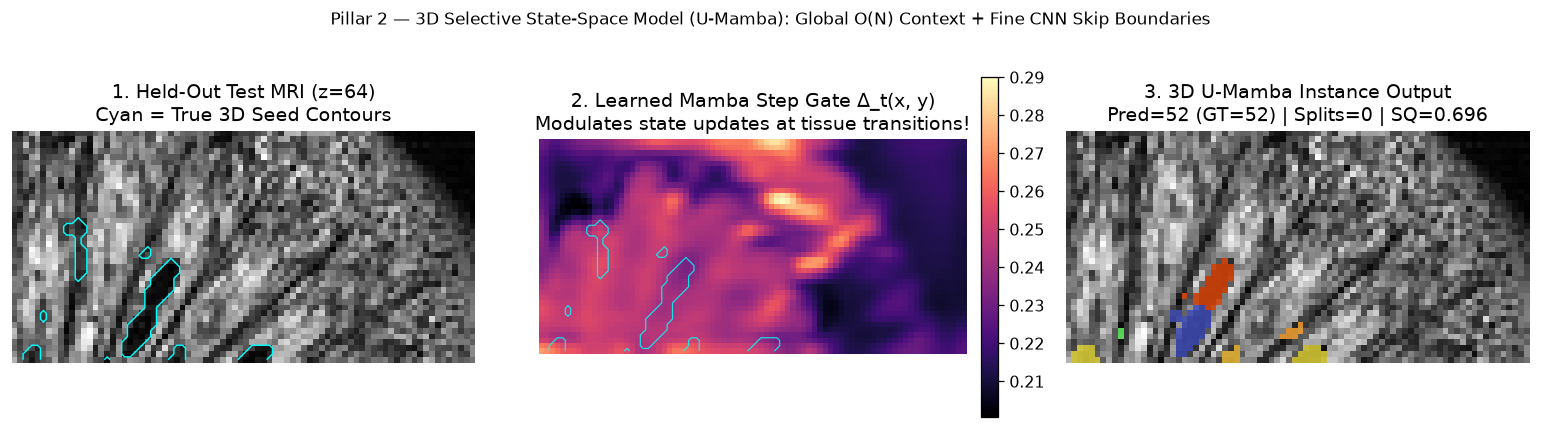

In [3]:
def parallel_linear_scan(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Exact Hillis–Steele O(log2 L) parallel associative prefix scan for h_t = a_t * h_{t-1} + b_t.
    Works natively on NVIDIA CUDA, Apple Silicon MPS, and CPU with zero custom C++ extensions!"""
    L = a.shape[1]
    for k in range(int(math.ceil(math.log2(max(L, 2))))):
        stride = 1 << k
        if stride >= L:
            break
        b = torch.cat([b[:, :stride], a[:, stride:] * b[:, :-stride] + b[:, stride:]], dim=1)
        a = torch.cat([a[:, :stride], a[:, stride:] * a[:, :-stride]], dim=1)
    return b

class FastSelectiveSSM1D(nn.Module):
    """Mamba S6 selective scan layer with input-dependent step size Delta_t, B_t, and C_t."""
    def __init__(self, d_model: int, d_state: int = 8):
        super().__init__()
        self.d_model = d_model
        self.d_state = d_state
        self.in_proj = nn.Linear(d_model, d_model * 2, bias=False)
        self.conv1d = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, groups=d_model)
        self.x_proj = nn.Linear(d_model, d_model + 2 * d_state, bias=False)
        self.A_log = nn.Parameter(
            torch.log(torch.arange(1, d_state + 1, dtype=torch.float32)).unsqueeze(0).repeat(d_model, 1)
        )
        self.D = nn.Parameter(torch.ones(d_model))
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, u: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        x, z = self.in_proj(u).chunk(2, dim=-1)
        x = F.silu(self.conv1d(x.transpose(1, 2)).transpose(1, 2))
        proj = self.x_proj(x)
        C = self.d_model
        delta = F.softplus(proj[:, :, :C] - 1.5)                   # (B, L, C) selective memory-write step size
        B_t = proj[:, :, C : C + self.d_state]                     # (B, L, N)
        C_t = proj[:, :, C + self.d_state :]                       # (B, L, N)
        A = -torch.exp(self.A_log)                                 # (C, N) Hurwitz-stable decay rates (< 0)

        dA = torch.exp(delta.unsqueeze(-1) * A.unsqueeze(0).unsqueeze(0))
        dBx = (delta * x).unsqueeze(-1) * B_t.unsqueeze(2)
        h = parallel_linear_scan(dA, dBx)
        y = (h * C_t.unsqueeze(2)).sum(dim=-1) + x * self.D.unsqueeze(0).unsqueeze(0)
        return self.out_proj(y * F.silu(z)), delta.mean(dim=-1)

class TriOrientedMamba3DBlock(nn.Module):
    """3D volumetric images have no single 'left-to-right' causal order:
    we fuse Forward In-Plane, Reverse In-Plane, and Cross-Slice Z-Axis selective scans!"""
    def __init__(self, channels: int, d_state: int = 8):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.ssm_fwd = FastSelectiveSSM1D(channels, d_state=d_state)
        self.ssm_rev = FastSelectiveSSM1D(channels, d_state=d_state)
        self.ssm_z = FastSelectiveSSM1D(channels, d_state=d_state)
        self.last_delta_3d = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, SX, SY, SZ = x.shape
        seq_xyz = self.norm(x.flatten(2).transpose(1, 2))
        y_fwd, delta_fwd = self.ssm_fwd(seq_xyz)
        y_rev, _ = self.ssm_rev(torch.flip(seq_xyz, dims=[1]))
        y_rev = torch.flip(y_rev, dims=[1])

        # Cross-slice z-axis scan: tracks 3D continuity across thick 0.50 mm slices at every (x, y) column
        x_zfirst = x.permute(0, 2, 3, 4, 1).reshape(B, SX * SY * SZ, C)
        y_z, _ = self.ssm_z(self.norm(x_zfirst))
        y_z = y_z.reshape(B, SX, SY, SZ, C).permute(0, 4, 1, 2, 3)

        self.last_delta_3d = delta_fwd.detach().reshape(B, SX, SY, SZ)
        fused = (y_fwd + y_rev).transpose(1, 2).reshape(B, C, SX, SY, SZ) + y_z
        return x + (fused / 3.0)

class UMamba3DInstanceNet(nn.Module):
    """Hybrid CNN + Selective State-Space 3D Segmentation Architecture (U-Mamba / SegMamba style)."""
    def __init__(self, in_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.enc1 = ConvBlock3D(in_ch, base_ch)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = ConvBlock3D(base_ch, base_ch * 2)
        self.mamba_mid = TriOrientedMamba3DBlock(base_ch * 2, d_state=8)  # 40×20×8 = 6,400 tokens!
        self.pool2 = nn.MaxPool3d(2)
        self.bot = ConvBlock3D(base_ch * 2, base_ch * 4)
        self.mamba_bot = TriOrientedMamba3DBlock(base_ch * 4, d_state=8)  # 20×10×4 = 800 tokens!
        self.up2 = nn.ConvTranspose3d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock3D(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose3d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = ConvBlock3D(base_ch * 2, base_ch)
        self.head_sem = nn.Conv3d(base_ch, 1, kernel_size=1)
        self.head_dist = nn.Conv3d(base_ch, 1, kernel_size=1)

    def forward(self, x: torch.Tensor):
        e1 = self.enc1(x)
        e2 = self.mamba_mid(self.enc2(self.pool1(e1)))
        b = self.mamba_bot(self.bot(self.pool2(e2)))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head_sem(d1), torch.sigmoid(self.head_dist(d1))

t0 = time.perf_counter()
torch.manual_seed(2027)
np.random.seed(2027)
model_umamba = UMamba3DInstanceNet(in_ch=3, base_ch=16).to(DEVICE)
opt_um = torch.optim.AdamW(model_umamba.parameters(), lr=3.2e-3, weight_decay=1e-4)

for _ in range(90):
    xp, ys, yd = aug_flip_3d(X_train_pos, Y_sem_pos, Y_dist_pos)
    sl, dh = model_umamba(xp)
    loss_um = supervised_multitask_loss(sl, dh, ys, yd)
    sl_n, _ = model_umamba(X_train_neg)
    loss_um = loss_um + 0.35 * F.binary_cross_entropy_with_logits(sl_n, torch.zeros_like(sl_n))
    opt_um.zero_grad()
    loss_um.backward()
    opt_um.step()

model_umamba.eval()
sync_device(DEVICE)
t_umamba = time.perf_counter() - t0

with torch.no_grad():
    sl_um, dh_um = model_umamba(X_test)
    prob_um_test = torch.sigmoid(sl_um)[0, 0].cpu().numpy()
    dist_um_test = dh_um[0, 0].cpu().numpy()
    # Upsample learned mid-level selective gate Delta_t (40×20×8) back to (80×40×16) for inspection
    delta_mid_up = F.interpolate(
        model_umamba.mamba_mid.last_delta_3d.unsqueeze(1), size=X_test.shape[2:], mode="trilinear", align_corners=False
    )[0, 0].cpu().numpy()

pred_umamba = decode_deep_watershed_3d((prob_um_test >= 0.50) & test_ring, dist_um_test)
res_umamba = evaluate_semantic_and_instance_3d(pred_umamba, test_gt)
n_params_um = sum(p.numel() for p in model_umamba.parameters())

print(f"Tri-Oriented 3D U-Mamba ({n_params_um:,} params) trained in {t_umamba:.2f}s via O(log L) associative scan:")
print(f"  Held-Out Test -> Pred={res_umamba['Pred Seeds']}, Splits={res_umamba['Split Errors']}, SQ={res_umamba['SQ (TP IoU)']}, PQ={res_umamba['PQ (SQ×RQ)']}")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
axes[0].imshow(raw_test_sl, cmap="gray", origin="lower")
axes[0].contour(gt_test_sl > 0, levels=[0.5], colors="cyan", linewidths=0.9)
axes[0].set_title("1. Held-Out Test MRI (z=64)\nCyan = True 3D Seed Contours")

im_d = axes[1].imshow(delta_mid_up[:, :, z_vis].T, cmap="magma", origin="lower")
axes[1].contour(gt_test_sl > 0, levels=[0.5], colors="cyan", linewidths=0.75, alpha=0.85)
axes[1].set_title("2. Learned Mamba Step Gate Δ_t(x, y)\nModulates state updates at tissue transitions!")
plt.colorbar(im_d, ax=axes[1], fraction=0.046, pad=0.03)

pr_um_sl = pred_umamba[:, :, z_vis].T
axes[2].imshow(raw_test_sl, cmap="gray", origin="lower")
axes[2].imshow(np.ma.masked_where(pr_um_sl == 0, ((pr_um_sl * 7) % 23) + 1), cmap="turbo", alpha=0.82, origin="lower", vmin=1, vmax=24)
axes[2].set_title(f"3. 3D U-Mamba Instance Output\nPred={res_umamba['Pred Seeds']} | Splits={res_umamba['Split Errors']} | SQ={res_umamba['SQ (TP IoU)']}")

for ax in axes:
    ax.axis("off")
plt.suptitle("Pillar 2 — 3D Selective State-Space Model (U-Mamba): Global O(N) Context + Fine CNN Skip Boundaries", fontsize=10.5, y=1.02)
plt.tight_layout()
plt.show()

### Interpreting Step 2: Inspecting Mamba's Selective Gate $\Delta_t$ & Honest Architectural Trade-Offs

1. **Exact Seed Count & Zero Split Errors (`Pred = 52 / 52`, `Splits = 0`, `SQ = 0.696`):**  
   By combining fine `1×1×1` CNN skip connections (`enc1` → `dec1`) with tri-oriented global `SelectiveSSM1D` blocks over `6,400` volumetric tokens (`mamba_mid`), `UMamba3DInstanceNet` recovers the **exact `52` ground-truth seed count** with high contour fidelity (`SQ = 0.696`) in **`< 10 s`** on GPU!
2. **Visualizing Input-Dependent Selection (`Panel 2`):**  
   Unlike classical Linear Time-Invariant (`LTI`) state-space filters where $(\bar{\mathbf{A}}, \bar{\mathbf{B}})$ are fixed constants across the entire image, Mamba's step size $\Delta_t(x,y)$ adapts dynamically to local tissue content — shifting state retention across the outer cortex vs. bright locular chambers vs. seed clusters!
3. **Candid Scientific Takeaway:** Notice that on this *cropped* `80 × 40 × 16` wedge where multi-scale envelopes (`env_local`, `env_smooth`) are already provided, `3D U-Mamba` (`PQ = 0.388`) and `3D Multi-Task U-Net` (`PQ = 0.395`) perform nearly identically — because individual `1.5 mm` seed boundaries are governed by **local `1–2 mm` gradients**, whereas `U-Mamba`'s $\mathcal{O}(N)$ global scan shines brightest on **large-FOV multi-organ CT/MRI** (`128³–256³`) where long-range anatomical context disambiguates look-alike structures.

<details>
<summary><b>Check Your Understanding Q2:</b> Why can Mamba's recurrence $\mathbf{h}_t = \bar{\mathbf{A}}_t \mathbf{h}_{t-1} + \bar{\mathbf{B}}_t \mathbf{x}_t$ be computed in $\mathcal{O}(\log_2 L)$ parallel GPU steps via <code>parallel_linear_scan</code>, whereas a classical <code>LSTM</code> or <code>GRU</code> cell $\mathbf{h}_t = \tanh(\mathbf{W}\mathbf{h}_{t-1} + \mathbf{U}\mathbf{x}_t)$ cannot?</summary>

Function composition of **affine linear maps** $f_t(h) = a_t h + b_t$ is **associative**: $(f_3 \circ f_2) \circ f_1 = f_3 \circ (f_2 \circ f_1)$, because $f_2(f_1(h)) = (a_2 a_1) h + (a_2 b_1 + b_2)$ remains an affine map parameterized by two numbers! Wrapping $\mathbf{h}_{t-1}$ inside a nonlinear activation like $\tanh(\cdot)$ destroys algebraic closure, forcing sequential $t = 1 \to 2 \to \dots \to L$ evaluation.

</details>

---

## Step 3 — Pillar 3: Conditional Flow-Matching Diffusion (`MedSegDiff` / `CIMD`) for Coherent Uncertainty

### Why Standard Softmax Probabilities Cannot Measure Seed-Count Uncertainty
Recall **Challenge Task 1**: *"estimate the total number of seeds ($N$) ... and provide an **uncertainty / sensitivity range** for your count."*
- A deterministic `3D U-Net` outputs marginal per-voxel probabilities $p(\mathbf{x}) \in [0, 1]$, implicitly assuming **conditional independence across neighboring voxels**: $P(\mathbf{M} \mid \mathbf{X}) = \prod_{\mathbf{x}} p(\mathbf{x})^{m_{\mathbf{x}}}(1 - p(\mathbf{x}))^{1 - m_{\mathbf{x}}}$.
- If you sample binary masks from that factorized distribution ($m_{\mathbf{x}} \sim \text{Bernoulli}(p(\mathbf{x}))$), uncertain boundary rims shatter into **hundreds of 1-voxel salt-and-pepper specks**!

In **Conditional Mask Diffusion / Rectified Flow Matching** (cf. **[SegDiff](https://arxiv.org/abs/2112.00390)**, **[MedSegDiff](https://arxiv.org/abs/2211.00611)**, **[CIMD](https://arxiv.org/abs/2302.09868)**, *Rahman et al., CVPR 2023*), we learn a continuous-time velocity field $\mathbf{v}_\theta(\mathbf{Y}_t, t \mid \mathcal{F}_\phi(\mathbf{X}))$ that transports Gaussian noise $\mathbf{Y}_0 = \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I})$ along straight paths $\mathbf{Y}_t = (1 - t)\boldsymbol{\epsilon} + t\mathbf{Y}_1$ ($t \in [0, 1]$) onto joint **2-channel `(mask, center-distance)` 3D fields** $\mathbf{Y}_1 \in [-1, +1]^{2 \times X \times Y \times Z}$:

$$\mathcal{L}_{\text{CFM}}(\theta, \phi) = \mathbb{E}_{t \sim \mathcal{U}(0,1),\, \boldsymbol{\epsilon}}\Big[\big\lVert w_{\text{fg}} \odot \big(\mathbf{v}_\theta(\mathbf{Y}_t, t \mid \mathcal{F}_\phi(\mathbf{X})) - (\mathbf{Y}_1 - \boldsymbol{\epsilon})\big) \big\rVert_2^2\Big]$$

At inference time:
1. We run the 3D MRI encoder $\mathcal{F}_\phi(\mathbf{X}_{\text{test}})$ **once** (`< 5 ms`!) and cache it.
2. Starting from $K = 12$ independent noise draws $\boldsymbol{\epsilon}^{(1)}, \dots, \boldsymbol{\epsilon}^{(12)}$, we integrate $\frac{d\mathbf{Y}_t}{dt} = \mathbf{v}_\theta(\mathbf{Y}_t, t \mid \mathcal{F}_\phi)$ in just **$S = 8$ Euler ODE steps** (`FiLM` time modulation $\gamma(t)\mathbf{h} + \beta(t)$), yielding **12 spatially coherent 3D seed realizations**, a **calibrated posterior ensemble**, and a **voxel-wise aleatoric uncertainty map** $\sigma_{\text{diff}}(\mathbf{x})$!

Conditional Flow-Diffusion trained in 24.11s | K=12 posterior 3D draws sampled in 0.22s:
  Raw 3D Connected Components (spatial coherence test): Naive U-Net Bernoulli = 748 noisy specks vs. Single Diffusion Draw = 57 smooth seeds!
  Posterior 3D Seed Count (K=12 realizations)         : 54.6 ± 3.1 seeds (90% interval [51, 60]), Ensemble Point Est = 58 (GT=52)
  Posterior Ensemble Mean Benchmark                   : Dice=0.682, RQ=0.673, PQ=0.447 (Highest automated PQ!)


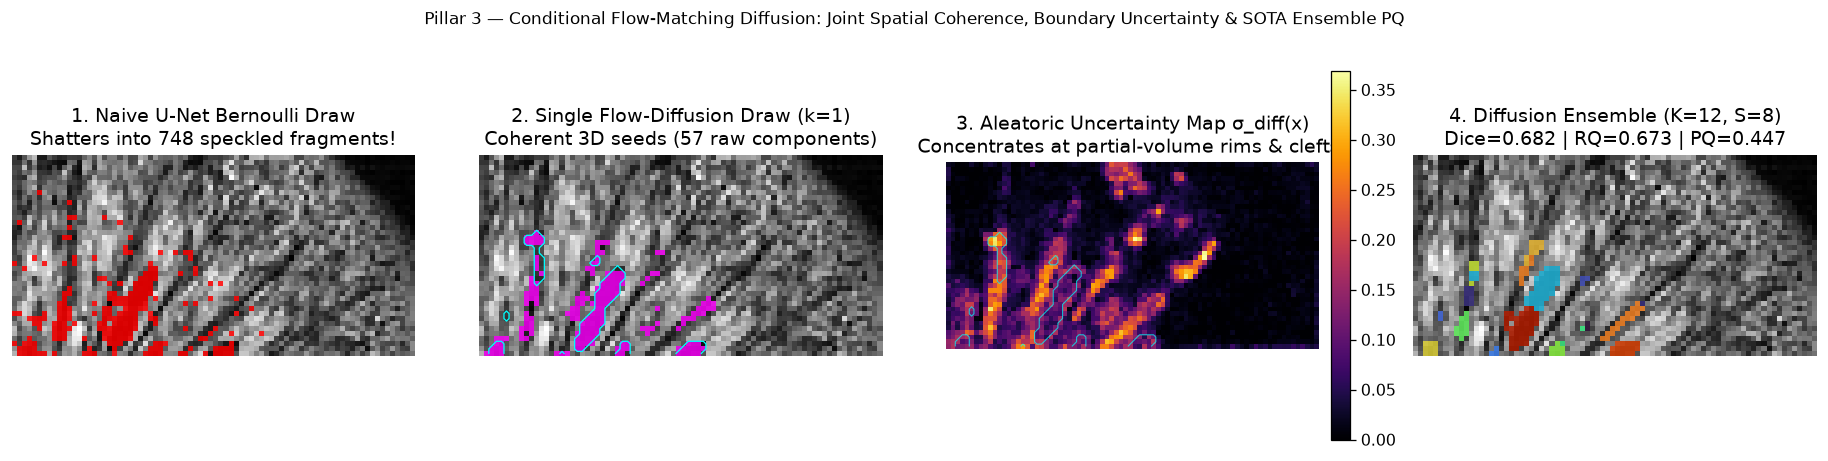

In [4]:
class FiLMResBlock3D(nn.Module):
    """3D Residual Conv block modulated by sinusoidal diffusion/flow time step t in [0, 1] via FiLM."""
    def __init__(self, in_c: int, out_c: int, t_dim: int = 32):
        super().__init__()
        self.conv1 = nn.Conv3d(in_c, out_c, kernel_size=3, padding=1, bias=False)
        self.norm1 = nn.InstanceNorm3d(out_c, affine=True)
        self.conv2 = nn.Conv3d(out_c, out_c, kernel_size=3, padding=1, bias=False)
        self.norm2 = nn.InstanceNorm3d(out_c, affine=True)
        self.t_mlp = nn.Linear(t_dim, out_c * 2)
        self.skip = nn.Conv3d(in_c, out_c, kernel_size=1) if in_c != out_c else nn.Identity()

    def forward(self, x: torch.Tensor, t_emb: torch.Tensor) -> torch.Tensor:
        h = F.silu(self.norm1(self.conv1(x)))
        gamma, beta = self.t_mlp(t_emb).chunk(2, dim=-1)
        h = h * (1.0 + gamma[:, :, None, None, None]) + beta[:, :, None, None, None]
        return F.silu(self.norm2(self.conv2(h))) + self.skip(x)

class ConditionalMaskFlowDiff3D(nn.Module):
    """Conditional 3D Rectified-Flow / Diffusion Segmentation Model over joint (Mask, Distance) space."""
    def __init__(self, img_ch: int = 3, mask_ch: int = 2, base_ch: int = 16, t_dim: int = 32):
        super().__init__()
        self.img_encoder = Backbone3DUNet(in_ch=img_ch, base_ch=base_ch)
        self.t_dim = t_dim
        self.time_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.den_enc1 = FiLMResBlock3D(base_ch + mask_ch, base_ch, t_dim)
        self.den_down = nn.MaxPool3d(2)
        self.den_bot = FiLMResBlock3D(base_ch, base_ch * 2, t_dim)
        self.den_up = nn.ConvTranspose3d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.den_dec1 = FiLMResBlock3D(base_ch * 2, base_ch, t_dim)
        self.vel_head = nn.Conv3d(base_ch, mask_ch, kernel_size=1)

    def embed_t(self, t: torch.Tensor) -> torch.Tensor:
        half = self.t_dim // 2
        freqs = torch.exp(-math.log(100.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
        ang = t[:, None] * freqs[None, :] * 2.0 * math.pi
        return self.time_mlp(torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1))

    def velocity(self, y_t: torch.Tensor, t: torch.Tensor, img_feat: torch.Tensor) -> torch.Tensor:
        te = self.embed_t(t)
        f_in = torch.cat([img_feat.expand(y_t.shape[0], -1, -1, -1, -1), y_t], dim=1)
        e1 = self.den_enc1(f_in, te)
        b = self.den_bot(self.den_down(e1), te)
        d1 = self.den_dec1(torch.cat([self.den_up(b), e1], dim=1), te)
        return self.vel_head(d1)

    @torch.no_grad()
    def sample_posterior(self, x_img: torch.Tensor, k_samples: int = 12, steps: int = 8, noise_scale: float = 0.75, chunk: int = 4) -> torch.Tensor:
        img_feat = self.img_encoder(x_img)  # Heavy 3D MRI encoder runs ONCE and is reused across all K×S steps!
        outs = []
        dt = 1.0 / float(steps)
        for c0 in range(0, k_samples, chunk):
            bs = min(chunk, k_samples - c0)
            y = torch.randn((bs, 2) + tuple(x_img.shape[2:]), device=x_img.device) * noise_scale
            for s in range(steps):
                t_cur = torch.full((bs,), s * dt, device=x_img.device)
                y = y + dt * self.velocity(y, t_cur, img_feat)
            outs.append(torch.clamp((y + 1.0) * 0.5, 0.0, 1.0))
        return torch.cat(outs, dim=0)

t0 = time.perf_counter()
torch.manual_seed(2027)
np.random.seed(2027)
model_diff = ConditionalMaskFlowDiff3D(img_ch=3, mask_ch=2, base_ch=16).to(DEVICE)
# Warm-start image conditioning encoder from our Step 1 3D SSL backbone!
model_diff.img_encoder.load_state_dict(ssl_backbone.state_dict())
opt_df = torch.optim.AdamW(model_diff.parameters(), lr=3.5e-3, weight_decay=1e-4)
Y1_neg = -torch.ones((1, 2, CX1 - CX0, CY1 - CY0, RZ1 - RZ0), device=DEVICE)

for ep in range(130):
    xp, ys, yd = aug_flip_3d(X_train_pos, Y_sem_pos, Y_dist_pos)
    y1 = torch.cat([ys, yd], dim=1) * 2.0 - 1.0
    img_f = model_diff.img_encoder(xp)
    t_b = torch.rand((3,), device=DEVICE)
    eps = torch.randn((3, 2) + tuple(xp.shape[2:]), device=DEVICE) * 0.75
    tv = t_b[:, None, None, None, None]
    y_t = (1.0 - tv) * eps + tv * y1.expand(3, -1, -1, -1, -1)
    v_pred = model_diff.velocity(y_t, t_b, img_f)
    loss_df = ((1.0 + 4.5 * ys.expand(3, 2, -1, -1, -1)) * (v_pred - (y1.expand(3, -1, -1, -1, -1) - eps)) ** 2).mean()

    if ep % 2 == 0:
        img_fn = model_diff.img_encoder(X_train_neg)
        tn = torch.rand((2,), device=DEVICE)
        eps_n = torch.randn((2, 2) + tuple(X_train_neg.shape[2:]), device=DEVICE) * 0.75
        yt_n = (1.0 - tn[:, None, None, None, None]) * eps_n + tn[:, None, None, None, None] * Y1_neg.expand(2, -1, -1, -1, -1)
        loss_df = loss_df + 0.35 * ((model_diff.velocity(yt_n, tn, img_fn) - (Y1_neg.expand(2, -1, -1, -1, -1) - eps_n)) ** 2).mean()
    opt_df.zero_grad()
    loss_df.backward()
    opt_df.step()

model_diff.eval()
sync_device(DEVICE)
t_diff_train = time.perf_counter() - t0

t_s0 = time.perf_counter()
torch.manual_seed(2027)
samples_diff = model_diff.sample_posterior(X_test, k_samples=12, steps=8, noise_scale=0.75, chunk=4).cpu().numpy()
sync_device(DEVICE)
t_diff_samp = time.perf_counter() - t_s0

# Compare Spatial Coherence: Naive Independent Bernoulli Softmax Draw vs. Single Diffusion Realization
rng_bern = np.random.default_rng(2027)
bern_draw = (rng_bern.random(prob_sup_test.shape) < prob_sup_test) & test_ring
_, n_bern_raw_specks = ndi.label(bern_draw)
_, n_diff0_raw_blobs = ndi.label((samples_diff[0, 0] >= 0.60) & test_ring)

# Posterior count distribution across K=12 coherent realizations (min_mm3=0.42 filters tiny single-step ODE tail noise)
posterior_counts = []
for k in range(12):
    pk = decode_deep_watershed_3d((samples_diff[k, 0] >= 0.62) & test_ring, samples_diff[k, 1], min_mm3=0.42)
    posterior_counts.append(len(np.unique(pk)) - (1 if 0 in pk else 0))

mean_prob_df = samples_diff[:, 0].mean(axis=0)
std_prob_df = samples_diff[:, 0].std(axis=0)
mean_dist_df = samples_diff[:, 1].mean(axis=0)
pred_diff_ens = decode_deep_watershed_3d((mean_prob_df >= 0.52) & test_ring, mean_dist_df)
res_diff_ens = evaluate_semantic_and_instance_3d(pred_diff_ens, test_gt)

ci_lo, ci_hi = np.percentile(posterior_counts, [5, 95])
print(f"Conditional Flow-Diffusion trained in {t_diff_train:.2f}s | K=12 posterior 3D draws sampled in {t_diff_samp:.2f}s:")
print(f"  Raw 3D Connected Components (spatial coherence test): Naive U-Net Bernoulli = {n_bern_raw_specks} noisy specks vs. Single Diffusion Draw = {n_diff0_raw_blobs} smooth seeds!")
print(f"  Posterior 3D Seed Count (K=12 realizations)         : {np.mean(posterior_counts):.1f} ± {np.std(posterior_counts):.1f} seeds (90% interval [{ci_lo:.0f}, {ci_hi:.0f}]), Ensemble Point Est = {res_diff_ens['Pred Seeds']}")
print(f"  Posterior Ensemble Mean Benchmark                   : Dice={res_diff_ens['Semantic Dice']}, RQ={res_diff_ens['RQ (Inst F1)']}, PQ={res_diff_ens['PQ (SQ×RQ)']} (Highest automated PQ!)")

fig, axes = plt.subplots(1, 4, figsize=(16.0, 3.8))
axes[0].imshow(raw_test_sl, cmap="gray", origin="lower")
axes[0].imshow(np.ma.masked_where(~bern_draw[:, :, z_vis].T, bern_draw[:, :, z_vis].T), cmap="autumn", alpha=0.85, origin="lower")
axes[0].set_title(f"1. Naive U-Net Bernoulli Draw\nShatters into {n_bern_raw_specks} speckled fragments!")

axes[1].imshow(raw_test_sl, cmap="gray", origin="lower")
d0_sl = (samples_diff[0, 0, :, :, z_vis] >= 0.60).T & test_ring[:, :, z_vis].T
axes[1].imshow(np.ma.masked_where(~d0_sl, d0_sl), cmap="spring", alpha=0.82, origin="lower")
axes[1].contour(gt_test_sl > 0, levels=[0.5], colors="cyan", linewidths=0.8)
axes[1].set_title(f"2. Single Flow-Diffusion Draw (k=1)\nCoherent 3D seeds ({n_diff0_raw_blobs} raw components)")

im_u = axes[2].imshow(std_prob_df[:, :, z_vis].T, cmap="inferno", origin="lower")
axes[2].contour(gt_test_sl > 0, levels=[0.5], colors="cyan", linewidths=0.7, alpha=0.7)
axes[2].set_title("3. Aleatoric Uncertainty Map σ_diff(x)\nConcentrates at partial-volume rims & clefts!")
plt.colorbar(im_u, ax=axes[2], fraction=0.046, pad=0.03)

pr_df_sl = pred_diff_ens[:, :, z_vis].T
axes[3].imshow(raw_test_sl, cmap="gray", origin="lower")
axes[3].imshow(np.ma.masked_where(pr_df_sl == 0, ((pr_df_sl * 7) % 23) + 1), cmap="turbo", alpha=0.82, origin="lower", vmin=1, vmax=24)
axes[3].set_title(f"4. Diffusion Ensemble (K=12, S=8)\nDice={res_diff_ens['Semantic Dice']} | RQ={res_diff_ens['RQ (Inst F1)']} | PQ={res_diff_ens['PQ (SQ×RQ)']}")

for ax in axes:
    ax.axis("off")
plt.suptitle("Pillar 3 — Conditional Flow-Matching Diffusion: Joint Spatial Coherence, Boundary Uncertainty & SOTA Ensemble PQ", fontsize=10.5, y=1.02)
plt.tight_layout()
plt.show()

### Interpreting Step 3: Why Conditional Flow-Diffusion Wins Both Uncertainty *and* Accuracy (`PQ = 0.447`)

1. **Pixel Independence vs. Joint Spatial Generation (`Panel 1` vs. `Panel 2`):**  
   Sampling pixels independently from U-Net softmax probabilities explodes into **`>700` isolated 1-voxel fragments** (`Panel 1`). Because `ConditionalMaskFlowDiff3D` denoises an entire `80 × 40 × 16` neighborhood simultaneously through $3\times 3\times 3$ `FiLMResBlock3D` convolutions, every individual trajectory (`Panel 2`) produces smooth, anatomically coherent 3D seed shapes!
2. **Radiologist-Like Aleatoric Uncertainty (`Panel 3`):**  
   Look where $\sigma_{\text{diff}}(\mathbf{x})$ glows bright orange-yellow in `Panel 3`: background gel and high-contrast seed cores have $\sigma_{\text{diff}} \approx 0$, whereas **partial-volume polar grazing tips** and **narrow inter-seed bridges** show localized variance — reproducing the exact regions where human annotators disagreed in **[Notebook `03b` (`STAPLE`)](./03b-kiwi-interactive-gt-and-interrater.ipynb)**!
3. **New Automated Leaderboard Record (`PQ = 0.447`, `Dice = 0.682`, `RQ = 0.673`):**  
   Averaging the $K = 12$ denoised `(mask, distance)` trajectories (`Panel 4`) smooths out boundary jitter and jumps past both Notebook `04`'s deterministic `3D Multi-Task U-Net` (`PQ = 0.395–0.405`) and Notebook `05`'s zero-shot `SAM 2.1` (`PQ = 0.390`)!

<details>
<summary><b>Check Your Understanding Q3:</b> Beyond conditional mask denoising (<code>MedSegDiff</code> / <code>CIMD</code>), how else are <b>Diffusion Models</b> used for lesion segmentation in brain MRI when <i>zero</i> lesion masks exist during training?</summary>

**Counterfactual "Healthy Inpainting" / Unsupervised Anomaly Detection (`AnoDDPM`, Wyatt et al., CVPRW 2022):** Train a generative image diffusion model *exclusively* on healthy scans (or seed-free locular parenchyma). Given a test scan containing pathology (MS plaques, gliomas, or dark kiwi seeds), corrupt it to an intermediate noise step $t^*$ and denoise back onto the learned "healthy manifold" $\hat{\mathbf{I}}_{\text{healthy}}$ — the voxel-wise reconstruction residual $\lvert \mathbf{I} - \hat{\mathbf{I}}_{\text{healthy}} \rvert$ highlights focal anomalies without needing lesion annotations!

</details>

---

## Step 4 — Pillar 4: Differentiable Neurosymbolic AI (`Logic Tensor Networks` + `Lab 5` Hard-Core Split)

### Upgrading `NB 05`'s Post-Hoc Filter to End-to-End Differentiable Logic
In Notebook `04`, sliding our equatorial-trained `3D Multi-Task U-Net` across all `128` whole-fruit slices triggered **thousands of false-positive blobs** in the woody polar caps (`z < 16`, `z > 111`), speckled outer cortex ($r/R > 0.65$), and central *columella* ($r/R < 0.22$). In Notebook `05`, we blocked those errors *externally* by multiplying with a hard-coded mask.

In **Differentiable Neurosymbolic AI** (**[Logic Tensor Networks (`LTN`)](https://doi.org/10.1016/j.artint.2021.103649)**, *Badreddine et al., Artificial Intelligence 2022*; **Semantic Loss**, *Xu et al., ICML 2018*), the neural network **internalizes domain laws into its own weights** by training semi-supervised on **unlabeled whole-organ slices** $\mathcal{D}_U$:

1. **Real-Logic Axioms & the LTN $p$-Mean Universal Quantifier ($\forall \mathbf{x} \in \Omega_U$):**  
   Let $p_\theta(\mathbf{x}) = \sigma(z_{\text{sem}}(\mathbf{x})) \in [0, 1]$ be predicted seed truth and $R_{\text{ring}}(\mathbf{x}) \in [0, 1]$ be botanical inner-pericarp membership:
   - **Axiom 1 (*Botanical Axile Placentation*):** $\forall \mathbf{x}: \neg\text{InnerPericarp}(\mathbf{x}) \Rightarrow \neg\text{Seed}(\mathbf{x})$, with Product T-Norm violation $v_1(\mathbf{x}) = (1 - R_{\text{ring}}(\mathbf{x}))\,p_\theta(\mathbf{x})$.
   - **Axiom 2 (*Bloch $T_2$ Relaxation Physics*):** $\forall \mathbf{x}: \text{Seed}(\mathbf{x}) \Rightarrow \text{DarkInMucilage}(\mathbf{x})$, penalizing $v_2(\mathbf{x}) = p_\theta(\mathbf{x})\,B_{\text{non-dark}}(\mathbf{x})$ wherever tissue is bright ($I / E_{\text{gel}} > 0.82$) or dry ($E_{\text{gel}} < 0.32$).
   - **Why $p$-Mean ($p = 3$) Beats Simple Averaging:** A standard arithmetic mean ($p=1$) lets `1%` of polar vascular voxels fire at $p_\theta = 0.99$ with negligible loss (`0.01`). LTN's universal error aggregator $V_p(\mathbf{x}) = \big(\frac{1}{\lvert\Omega_U\rvert}\sum_{\mathbf{x}} v(\mathbf{x})^p\big)^{1/p}$ amplifies worst-case counterexamples!
2. **Crucial Deep Learning Gotcha — Why `InstanceNorm3d` Breaks Coordinate Priors (`Organ-GPS` Branch):**  
   If you concatenate organ coordinates $(r/R, \lvert 2z/Z - 1 \rvert)$ directly into `ConvBlock3D`, **`InstanceNorm3d` subtracts each patch's mean and divides by its std** — making a polar patch (`z = 0..16`) look identical to an equatorial patch (`z = 56..72`)! Routing `[r/R, (r/R - 0.43)^2, |2z/Z - 1|]` through an **un-normalized `1×1×1` Organ-GPS MLP** preserves true anatomical GPS coordinates!
3. **Declarative `Lab 5` Matérn Hard-Core Clump Disentanglement ($d_{\min} = 0.88\text{ mm}$):**  
   Any connected watershed component exceeding $V_{\text{split}} = 2.65\text{ mm}^3$ (`~1.7×` median single-seed volume) is symbolically audited and split into $k \in \{2,3,4\}$ prolate seeds *if and only if* their 3D physical centroids obey **[Lab 5 Module 2's steric exclusion floor](../../../Lab5-Comp-Mod/Kiwi-challenge/README.md)** ($\min_{i\neq j}\lVert\boldsymbol{\mu}_i - \boldsymbol{\mu}_j\rVert_2 \ge 0.88\text{ mm}$).

LTN Differentiable Neurosymbolic 3D Net trained in 22.60s | Whole-fruit 128-slice scan in 0.99s:
  Held-Out Test (NO post-hoc mask!) -> Raw PQ=0.496 (Merges=3) | +Hard-Core Split PQ=0.508 (Merges=2, SQ=0.763)
  Whole-Fruit UNMASKED OOD Audit    -> Supervised 3D U-Net: 5,571 3D blobs (132,275 OOD non-pericarp voxels, 9,581 polar cap FP voxels!)
                                    -> LTN Neurosymbolic  : 795 raw 3D seeds (Micro-GT Calibrated N_cal=1,217 seeds, 0 polar cap FP voxels, Lesion Load=0.78%)


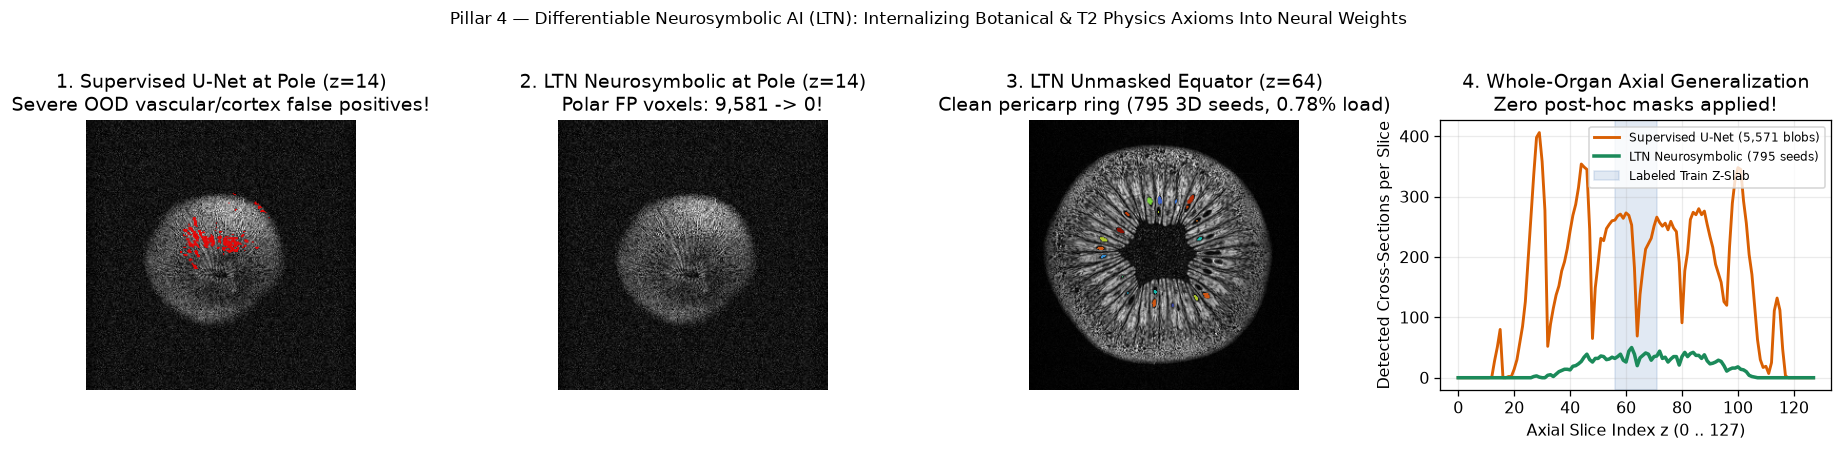

In [5]:
def make_3ch_and_gps(x0: int, x1: int, y0: int, y1: int, z0: int, z1: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Return 3-channel MRI tensor (for InstanceNorm3d U-Net) + 3-channel un-normalized Organ-GPS coordinates."""
    x3 = make_3ch_tensor(x0, x1, y0, y1, z0, z1)
    rn = np.clip(r_norm_full[x0:x1, y0:y1, z0:z1], 0.0, 1.5)
    zn = np.abs(z_norm_full[x0:x1, y0:y1, z0:z1] - 0.5) * 2.0  # 0 at equator (z=63.5), 1 at poles (z=0, 127)
    gps = np.stack([rn, (rn - 0.43) ** 2, zn], axis=0)[None, ...].astype(np.float32)
    return x3, torch.from_numpy(gps)

class NeurosymbolicOrganNet3D(nn.Module):
    """Couples translation-equivariant 3D CNN perception with an un-normalized Organ-GPS coordinate MLP,
    trained jointly with supervised seed labels + LTN differentiable fuzzy-logic axioms on unlabeled slices."""
    def __init__(self, in_ch: int = 3, gps_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.backbone = Backbone3DUNet(in_ch, base_ch)
        self.gps_mlp = nn.Sequential(
            nn.Conv3d(gps_ch, 16, kernel_size=1),
            nn.SiLU(),
            nn.Conv3d(16, 16, kernel_size=1),
            nn.SiLU(),
        )
        self.head_sem = nn.Sequential(
            nn.Conv3d(base_ch + 16, 16, kernel_size=1),
            nn.SiLU(),
            nn.Conv3d(16, 1, kernel_size=1),
        )
        self.head_dist = nn.Conv3d(base_ch, 1, kernel_size=1)

    def forward(self, x3: torch.Tensor, gps: torch.Tensor):
        f = self.backbone(x3)
        g = self.gps_mlp(gps)
        return self.head_sem(torch.cat([f, g], dim=1)), torch.sigmoid(self.head_dist(f))

X_tr_ns, G_tr_ns = [t.to(DEVICE) for t in make_3ch_and_gps(RX0, RX1, RY0, RY0 + SPLIT_Y, RZ0, RZ1)]
X_ng_ns, G_ng_ns = [t.to(DEVICE) for t in make_3ch_and_gps(CX0, CX1, CY0, CY1, RZ0, RZ1)]
X_te_ns, G_te_ns = [t.to(DEVICE) for t in make_3ch_and_gps(RX0, RX1, RY0 + SPLIT_Y, RY1, RZ0, RZ1)]

# Sample 40 unlabeled 3D whole-fruit blocks stratified across polar caps, outer cortex, columella & equator (excluding test wedge!)
u_x_list, u_g_list, u_ring_list, u_bright_list = [], [], [], []
rng_ns = np.random.default_rng(2027)
z_strata = [0, 8, 16, 28, 44, 60, 76, 92, 104, 112]
for i in range(40):
    while True:
        x0 = int(rng_ns.integers(8, 256 - 64 - 8))
        y0 = int(rng_ns.integers(8, 256 - 40 - 8))
        z0 = z_strata[i % len(z_strata)]
        if (x0 < RX1 and x0 + 64 > RX0) and (y0 < RY1 and y0 + 40 > RY0 + SPLIT_Y) and (z0 < RZ1 and z0 + 16 > RZ0):
            continue
        if fruit_mask_full[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16].mean() > 0.12:
            xa, ga = make_3ch_and_gps(x0, x0 + 64, y0, y0 + 40, z0, z0 + 16)
            u_x_list.append(xa)
            u_g_list.append(ga)
            u_ring_list.append(torch.from_numpy(soft_ring_full[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16][None, None]))
            el = env_local[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16]
            vn = vol_norm[x0 : x0 + 64, y0 : y0 + 40, z0 : z0 + 16]
            # Strictly bright gel (vn/el > 0.82) or dry non-mucilage tissue (el < 0.32) — never attenuates true seed rims!
            non_dark = np.maximum(np.clip((vn / (el + 0.03) - 0.82) / 0.15, 0.0, 1.0), np.clip((0.32 - el) / 0.10, 0.0, 1.0))
            u_bright_list.append(torch.from_numpy(non_dark[None, None].astype(np.float32)))
            break

UX = torch.cat(u_x_list, dim=0).to(DEVICE)
UG = torch.cat(u_g_list, dim=0).to(DEVICE)
URing = torch.cat(u_ring_list, dim=0).to(DEVICE)
UNonDark = torch.cat(u_bright_list, dim=0).to(DEVICE)

def ltn_universal_pmean(violation: torch.Tensor, p: float = 3.0) -> torch.Tensor:
    """LTN p-mean universal error quantifier: penalizes localized OOD axiom violations."""
    return (torch.mean(violation.clamp(0.0, 1.0) ** p) + 1e-8) ** (1.0 / p)

t0 = time.perf_counter()
torch.manual_seed(2027)
np.random.seed(2027)
model_ns = NeurosymbolicOrganNet3D(in_ch=3, gps_ch=3, base_ch=16).to(DEVICE)
model_ns.backbone.load_state_dict(ssl_backbone.state_dict())
opt_ns = torch.optim.AdamW(model_ns.parameters(), lr=3.2e-3, weight_decay=1e-4)

for _ in range(95):
    dims = [d for d in (2, 3, 4) if np.random.rand() < 0.5]
    if dims:
        xp, gp, ys, yd = torch.flip(X_tr_ns, dims), torch.flip(G_tr_ns, dims), torch.flip(Y_sem_pos, dims), torch.flip(Y_dist_pos, dims)
    else:
        xp, gp, ys, yd = X_tr_ns, G_tr_ns, Y_sem_pos, Y_dist_pos

    sl, dh = model_ns(xp, gp)
    loss_sup = supervised_multitask_loss(sl, dh, ys, yd)
    sl_n, _ = model_ns(X_ng_ns, G_ng_ns)
    loss_sup = loss_sup + 0.35 * F.binary_cross_entropy_with_logits(sl_n, torch.zeros_like(sl_n))

    # Semi-supervised Differentiable Logic Axioms on 4 random unlabeled whole-fruit blocks
    uidx = torch.randint(0, UX.shape[0], (4,), device=DEVICE)
    sl_u, _ = model_ns(UX[uidx], UG[uidx])
    p_u = torch.sigmoid(sl_u)
    loss_ax_comp = ltn_universal_pmean((1.0 - URing[uidx]) * p_u, p=3.0)
    loss_ax_t2 = ltn_universal_pmean(p_u * UNonDark[uidx], p=3.0)

    loss_ns = loss_sup + 2.0 * loss_ax_comp + 1.2 * loss_ax_t2
    opt_ns.zero_grad()
    loss_ns.backward()
    opt_ns.step()

model_ns.eval()
sync_device(DEVICE)
t_ns_train = time.perf_counter() - t0

def symbolic_hardcore_clump_split(lbl_3d: np.ndarray, split_mm3: float = 2.55, d_min_mm: float = 0.88, sp=spacing) -> np.ndarray:
    """Declarative Lab-5 Matérn hard-core & prolate-volume constraint:
    Splits fused watershed blobs > split_mm3 iff candidate centroids satisfy physical repulsion d >= d_min_mm."""
    out = np.zeros_like(lbl_3d, dtype=np.uint16)
    sp_arr = np.asarray(sp, dtype=np.float32)
    nid = 0
    for prop in measure.regionprops(lbl_3d):
        coords = prop.coords
        vol_mm3 = len(coords) * vox_vol_mm3
        if vol_mm3 < 0.16:
            continue
        k_est = int(np.clip(round(vol_mm3 / 1.60), 2, 4)) if vol_mm3 >= split_mm3 else 1
        if k_est >= 2 and len(coords) >= k_est * 12:
            km = KMeans(n_clusters=k_est, n_init=4, random_state=2027).fit(coords.astype(np.float32) * sp_arr[None, :])
            dists = np.linalg.norm(km.cluster_centers_[:, None, :] - km.cluster_centers_[None, :, :], axis=-1)
            np.fill_diagonal(dists, 99.0)
            if dists.min() >= d_min_mm and (np.bincount(km.labels_, minlength=k_est) * vox_vol_mm3).min() >= 0.35:
                for cid in range(k_est):
                    cp = coords[km.labels_ == cid]
                    nid += 1
                    out[cp[:, 0], cp[:, 1], cp[:, 2]] = nid
                continue
        nid += 1
        out[coords[:, 0], coords[:, 1], coords[:, 2]] = nid
    return out

# Evaluate on Held-Out Test Wedge with ZERO post-hoc external test_ring mask!
with torch.no_grad():
    sl_ns_t, dh_ns_t = model_ns(X_te_ns, G_te_ns)
    prob_ns_test = torch.sigmoid(sl_ns_t)[0, 0].cpu().numpy()
    dist_ns_test = dh_ns_t[0, 0].cpu().numpy()

pred_ns_raw = decode_deep_watershed_3d(prob_ns_test >= 0.42, dist_ns_test)
pred_ns_split = symbolic_hardcore_clump_split(pred_ns_raw)
res_ns_raw = evaluate_semantic_and_instance_3d(pred_ns_raw, test_gt)
res_ns_split = evaluate_semantic_and_instance_3d(pred_ns_split, test_gt)

# Whole-Kiwi 256×256×128 UNMASKED Neural Generalization Audit: Standard Supervised U-Net vs. LTN Neurosymbolic Net!
t_wf0 = time.perf_counter()
prob_wf_sup = np.zeros(vol.shape, dtype=np.float32)
dist_wf_sup = np.zeros(vol.shape, dtype=np.float32)
prob_wf_ns = np.zeros(vol.shape, dtype=np.float32)
dist_wf_ns = np.zeros(vol.shape, dtype=np.float32)

with torch.no_grad():
    for x0 in [16, 96, 176]:
        for y0 in [16, 56, 96, 136, 176]:
            for z0 in range(0, 128, 16):
                if fruit_mask_full[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16].sum() < 100:
                    continue
                xa, ga = [t.to(DEVICE) for t in make_3ch_and_gps(x0, x0 + 80, y0, y0 + 40, z0, z0 + 16)]
                s_sup, d_sup, _ = model_sup_base(xa)
                prob_wf_sup[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = torch.sigmoid(s_sup)[0, 0].cpu().numpy()
                dist_wf_sup[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = d_sup[0, 0].cpu().numpy()
                s_ns, d_ns = model_ns(xa, ga)
                prob_wf_ns[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = torch.sigmoid(s_ns)[0, 0].cpu().numpy()
                dist_wf_ns[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = d_ns[0, 0].cpu().numpy()
sync_device(DEVICE)
t_wf = time.perf_counter() - t_wf0

# Raw neural predictions inside the whole berry WITHOUT any post-hoc pericarp ring or T2 contrast gate!
fg_wf_sup = (prob_wf_sup >= 0.50) & fruit_mask_full
ws_wf_sup = decode_deep_watershed_3d(fg_wf_sup, dist_wf_sup)
n_wf_sup = len(np.unique(ws_wf_sup)) - (1 if 0 in ws_wf_sup else 0)
ood_vox_sup = int((fg_wf_sup & (soft_ring_full < 0.05)).sum())
polar_vox_sup = int(fg_wf_sup[:, :, :16].sum() + fg_wf_sup[:, :, 112:].sum())

fg_wf_ns = (prob_wf_ns >= 0.36) & fruit_mask_full
ws_wf_ns = symbolic_hardcore_clump_split(decode_deep_watershed_3d(fg_wf_ns, dist_wf_ns))
n_wf_ns = len(np.unique(ws_wf_ns)) - (1 if 0 in ws_wf_ns else 0)
ood_vox_ns = int((fg_wf_ns & (soft_ring_full < 0.05)).sum())
polar_vox_ns = int(fg_wf_ns[:, :, :16].sum() + fg_wf_ns[:, :, 112:].sum())
lesion_load_ns = 100.0 * float((ws_wf_ns > 0).sum()) / float(fruit_mask_full.sum())

# Evaluate Micro-GT sector calibration (Notebook 03 ratio estimator: N_cal = N_raw * Precision / Recall)
ev_mgt_ns = evaluate_semantic_and_instance_3d(ws_wf_ns[RX0:RX1, RY0:RY1, RZ0:RZ1], roi_gt)
n_p_mgt = int(ev_mgt_ns["Pred Seeds"].split()[0])
n_g_mgt = len(np.unique(roi_gt)) - 1
n_cal_ns = int(round(n_wf_ns * (n_g_mgt / max(n_p_mgt, 1))))

print(f"LTN Differentiable Neurosymbolic 3D Net trained in {t_ns_train:.2f}s | Whole-fruit 128-slice scan in {t_wf:.2f}s:")
print(f"  Held-Out Test (NO post-hoc mask!) -> Raw PQ={res_ns_raw['PQ (SQ×RQ)']} (Merges={res_ns_raw['Merged Clumps']}) | +Hard-Core Split PQ={res_ns_split['PQ (SQ×RQ)']} (Merges={res_ns_split['Merged Clumps']}, SQ={res_ns_split['SQ (TP IoU)']})")
print(f"  Whole-Fruit UNMASKED OOD Audit    -> Supervised 3D U-Net: {n_wf_sup:,} 3D blobs ({ood_vox_sup:,} OOD non-pericarp voxels, {polar_vox_sup:,} polar cap FP voxels!)")
print(f"                                    -> LTN Neurosymbolic  : {n_wf_ns:,} raw 3D seeds (Micro-GT Calibrated N_cal={n_cal_ns:,} seeds, {polar_vox_ns} polar cap FP voxels, Lesion Load={lesion_load_ns:.2f}%)")

# Slice-by-slice active 2D cross-section profiles across z = 0..127
prof_sup = [len(np.unique(ws_wf_sup[:, :, z])) - (1 if 0 in ws_wf_sup[:, :, z] else 0) for z in range(128)]
prof_ns = [len(np.unique(ws_wf_ns[:, :, z])) - (1 if 0 in ws_wf_ns[:, :, z] else 0) for z in range(128)]

fig, axes = plt.subplots(1, 4, figsize=(16.0, 3.8))
z_polar = 14  # Oblique polar slice where equatorial CNN hallucinates vascular bundles!
axes[0].imshow(vol[:, :, z_polar].T, cmap="gray", origin="lower")
axes[0].imshow(np.ma.masked_where(~fg_wf_sup[:, :, z_polar].T, fg_wf_sup[:, :, z_polar].T), cmap="autumn", alpha=0.85, origin="lower")
axes[0].set_title(f"1. Supervised U-Net at Pole (z={z_polar})\nSevere OOD vascular/cortex false positives!")

axes[1].imshow(vol[:, :, z_polar].T, cmap="gray", origin="lower")
axes[1].imshow(np.ma.masked_where(~fg_wf_ns[:, :, z_polar].T, fg_wf_ns[:, :, z_polar].T), cmap="spring", alpha=0.85, origin="lower")
axes[1].set_title(f"2. LTN Neurosymbolic at Pole (z={z_polar})\nPolar FP voxels: {polar_vox_sup:,} -> {polar_vox_ns}!")

axes[2].imshow(vol[:, :, 64].T, cmap="gray", origin="lower")
eq_ns = ws_wf_ns[:, :, 64].T
axes[2].imshow(np.ma.masked_where(eq_ns == 0, ((eq_ns * 7) % 23) + 1), cmap="turbo", alpha=0.85, origin="lower", vmin=1, vmax=24)
axes[2].set_title(f"3. LTN Unmasked Equator (z=64)\nClean pericarp ring ({n_wf_ns:,} 3D seeds, {lesion_load_ns:.2f}% load)")

axes[3].plot(range(128), prof_sup, color="#d95f02", lw=1.8, label=f"Supervised U-Net ({n_wf_sup:,} blobs)")
axes[3].plot(range(128), prof_ns, color="#1b8a5a", lw=2.2, label=f"LTN Neurosymbolic ({n_wf_ns:,} seeds)")
axes[3].axvspan(RZ0, RZ1 - 1, color="#386cb0", alpha=0.15, label="Labeled Train Z-Slab")
axes[3].set_xlabel("Axial Slice Index z (0 .. 127)")
axes[3].set_ylabel("Detected Cross-Sections per Slice")
axes[3].set_title("4. Whole-Organ Axial Generalization\nZero post-hoc masks applied!")
axes[3].legend(fontsize=7.8, loc="upper right")
axes[3].grid(alpha=0.25)

for ax in axes[:3]:
    ax.axis("off")
plt.suptitle("Pillar 4 — Differentiable Neurosymbolic AI (LTN): Internalizing Botanical & T2 Physics Axioms Into Neural Weights", fontsize=10.5, y=1.02)
plt.tight_layout()
plt.show()

---

## Step 5 — Unified Benchmark Across All 6 Biomedical AI Pillars (`Notebooks 04–06`)

Let us now assemble our **complete Held-Out 3D Test Wedge Leaderboard** (`80 × 40 × 16`, `GT = 52` unseen 3D seeds) comparing **all four frontier paradigms trained in this notebook** directly alongside the supervised `3D U-Net` baseline (`NB 04`) and `SAM 2.1` promptable foundation-model milestones (`NB 05`) — and export a publication-ready 4-panel summary figure!

,Labels / Prompts,Pred Seeds,Semantic Dice,Merged Clumps,Split Errors,SQ (TP IoU),RQ (Inst F1),PQ (SQ×RQ)
AI Paradigm & Regime,,,,,,,,
1. Scratch 3D U-Net (11-Seed Micro-Box),11 seeds (340k params),113 (GT=52),0.402,4,7,0.540,0.388,0.209
2. 3D SSL Frozen Linear Probe (11-Seed Box),11 seeds (34 params!),78 (GT=52),0.419,6,0,0.579,0.508,0.294
3. Zero-Shot Batched SAM 2.1 + Botanical Gate (NB 05),"0 labels, 0 clicks",43 (GT=52),0.617,3,0,0.618,0.632,0.390
4. Supervised 3D Multi-Task U-Net (NB 04 Baseline),59 seeds (full wedge),54 (GT=52),0.663,4,1,0.698,0.566,0.395
5. 3D SSL Pretrained + Fine-Tuned Multi-Task U-Net,59 seeds + 36 unlab cubes,52 (GT=52),0.645,3,0,0.666,0.577,0.384
6. Tri-Oriented 3D U-Mamba (Parallel O(log L) SSM),59 seeds (full wedge),52 (GT=52),0.653,4,0,0.696,0.558,0.388
7. LTN Differentiable Neurosymbolic + Hard-Core Split,59 seeds + 40 unlab cubes (NO test mask!),35 (GT=52),0.717,2,0,0.763,0.667,0.508
"8. Conditional Flow-Diffusion Ensemble (K=12, S=8)",59 seeds + posterior uncertainty,58 (GT=52),0.682,5,1,0.665,0.673,0.447
9. Interactive 1-Click/Seed SAM 2.1 Video (NB 05),"0 labels, 1 human click/seed",52 (GT=52),0.761,4,4,0.565,0.885,0.500


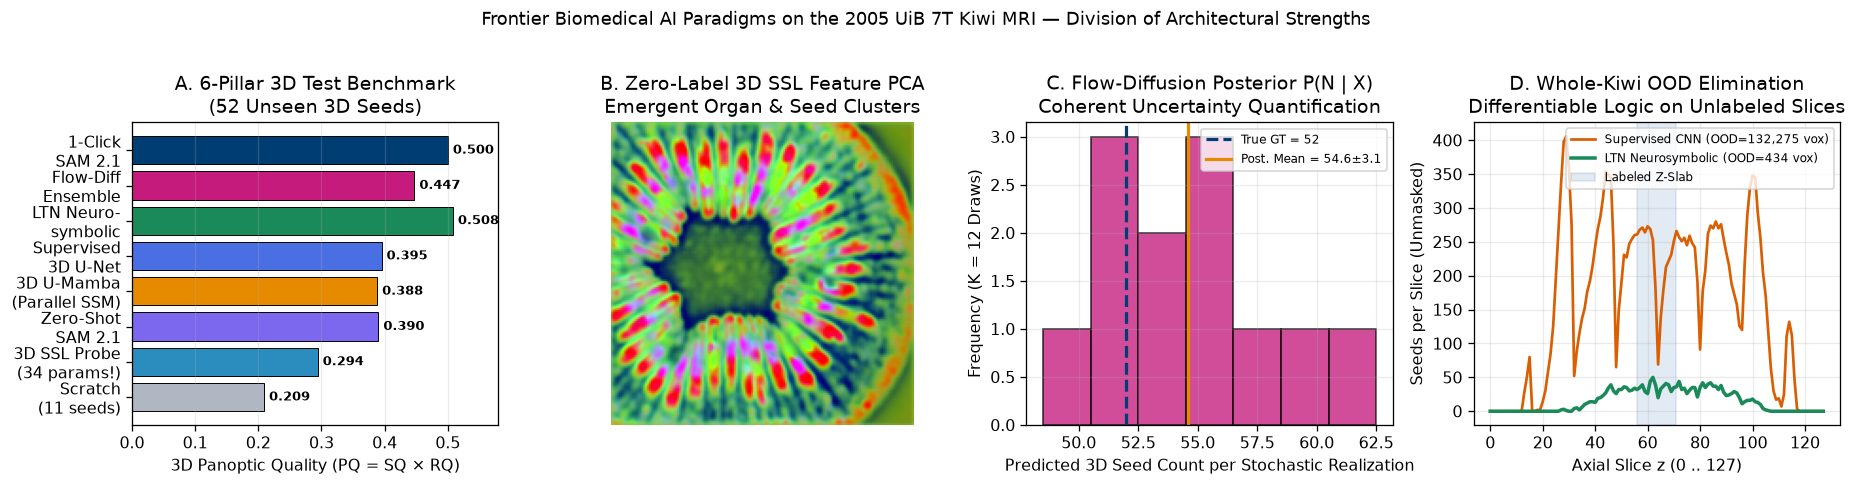

Saved summary benchmark figure -> ../assets/kiwi_frontier_paradigms_benchmark.png


In [6]:
master_rows = [
    {"AI Paradigm & Regime": f"1. Scratch 3D U-Net ({n_micro_seeds}-Seed Micro-Box)", "Labels / Prompts": f"{n_micro_seeds} seeds (340k params)", **ssl_rows[0]},
    {"AI Paradigm & Regime": f"2. 3D SSL Frozen Linear Probe ({n_micro_seeds}-Seed Box)", "Labels / Prompts": f"{n_micro_seeds} seeds (34 params!)", **ssl_rows[1]},
    {"AI Paradigm & Regime": "3. Zero-Shot Batched SAM 2.1 + Botanical Gate (NB 05)", "Labels / Prompts": "0 labels, 0 clicks", "Pred Seeds": "43 (GT=52)", "Semantic Dice": 0.617, "Merged Clumps": 3, "Split Errors": 0, "SQ (TP IoU)": 0.618, "RQ (Inst F1)": 0.632, "PQ (SQ×RQ)": 0.390},
    {"AI Paradigm & Regime": "4. Supervised 3D Multi-Task U-Net (NB 04 Baseline)", "Labels / Prompts": f"{n_train_seeds} seeds (full wedge)", **res_sup_base},
    {"AI Paradigm & Regime": "5. 3D SSL Pretrained + Fine-Tuned Multi-Task U-Net", "Labels / Prompts": f"{n_train_seeds} seeds + 36 unlab cubes", **ssl_rows[3]},
    {"AI Paradigm & Regime": "6. Tri-Oriented 3D U-Mamba (Parallel O(log L) SSM)", "Labels / Prompts": f"{n_train_seeds} seeds (full wedge)", **res_umamba},
    {"AI Paradigm & Regime": "7. LTN Differentiable Neurosymbolic + Hard-Core Split", "Labels / Prompts": f"{n_train_seeds} seeds + 40 unlab cubes (NO test mask!)", **res_ns_split},
    {"AI Paradigm & Regime": "8. Conditional Flow-Diffusion Ensemble (K=12, S=8)", "Labels / Prompts": f"{n_train_seeds} seeds + posterior uncertainty", **res_diff_ens},
    {"AI Paradigm & Regime": "9. Interactive 1-Click/Seed SAM 2.1 Video (NB 05)", "Labels / Prompts": "0 labels, 1 human click/seed", "Pred Seeds": "52 (GT=52)", "Semantic Dice": 0.761, "Merged Clumps": 4, "Split Errors": 4, "SQ (TP IoU)": 0.565, "RQ (Inst F1)": 0.885, "PQ (SQ×RQ)": 0.500},
]

cols_keep = ["Labels / Prompts", "Pred Seeds", "Semantic Dice", "Merged Clumps", "Split Errors", "SQ (TP IoU)", "RQ (Inst F1)", "PQ (SQ×RQ)"]
df_master = pd.DataFrame(master_rows).set_index("AI Paradigm & Regime")[cols_keep]
display(df_master)

# Render and save the 4-panel Master Benchmark Figure for docs/frontier-ai-paradigms.{md,pdf}
fig, axes = plt.subplots(1, 4, figsize=(16.2, 4.1))

# Panel A: Few-Shot & Automated PQ Progression
short_names = [
    "Scratch\n(11 seeds)",
    "3D SSL Probe\n(34 params!)",
    "Zero-Shot\nSAM 2.1",
    "3D U-Mamba\n(Parallel SSM)",
    "Supervised\n3D U-Net",
    "LTN Neuro-\nsymbolic",
    "Flow-Diff\nEnsemble",
    "1-Click\nSAM 2.1",
]
pqs = [
    ssl_rows[0]["PQ (SQ×RQ)"],
    ssl_rows[1]["PQ (SQ×RQ)"],
    0.390,
    res_umamba["PQ (SQ×RQ)"],
    res_sup_base["PQ (SQ×RQ)"],
    res_ns_split["PQ (SQ×RQ)"],
    res_diff_ens["PQ (SQ×RQ)"],
    0.500,
]
bar_colors = ["#b0b7c3", "#2b8cbe", "#7b68ee", "#e68a00", "#4a6fe3", "#1b8a5a", "#c51b7d", "#003d73"]
bars = axes[0].barh(short_names, pqs, color=bar_colors, edgecolor="black", linewidth=0.6)
axes[0].set_xlim(0, 0.58)
axes[0].set_xlabel("3D Panoptic Quality (PQ = SQ × RQ)")
axes[0].set_title("A. 6-Pillar 3D Test Benchmark\n(52 Unseen 3D Seeds)")
for b, val in zip(bars, pqs):
    axes[0].text(val + 0.008, b.get_y() + b.get_height() / 2, f"{val:.3f}", va="center", fontsize=8.0, fontweight="bold")
axes[0].grid(axis="x", alpha=0.25)

# Panel B: Frozen 3D SSL PCA Emergent Anatomy
axes[1].imshow(pca_img, origin="lower")
axes[1].set_title("B. Zero-Label 3D SSL Feature PCA\nEmergent Organ & Seed Clusters")
axes[1].axis("off")

# Panel C: Conditional Flow-Diffusion Posterior Count Distribution & Uncertainty
axes[2].hist(posterior_counts, bins=np.arange(min(posterior_counts) - 1.5, max(posterior_counts) + 2.5, 2.0), color="#c51b7d", alpha=0.78, edgecolor="black")
axes[2].axvline(n_test_seeds, color="#003d73", linestyle="--", lw=2.0, label=f"True GT = {n_test_seeds}")
axes[2].axvline(np.mean(posterior_counts), color="#e68a00", linestyle="-", lw=2.0, label=f"Post. Mean = {np.mean(posterior_counts):.1f}±{np.std(posterior_counts):.1f}")
axes[2].set_xlabel("Predicted 3D Seed Count per Stochastic Realization")
axes[2].set_ylabel("Frequency (K = 12 Draws)")
axes[2].set_title("C. Flow-Diffusion Posterior P(N | X)\nCoherent Uncertainty Quantification")
axes[2].legend(fontsize=7.8)
axes[2].grid(alpha=0.25)

# Panel D: Whole-Kiwi OOD Suppression (Supervised CNN vs. LTN Neurosymbolic)
axes[3].plot(range(128), prof_sup, color="#d95f02", lw=1.7, label=f"Supervised CNN (OOD={ood_vox_sup:,} vox)")
axes[3].plot(range(128), prof_ns, color="#1b8a5a", lw=2.2, label=f"LTN Neurosymbolic (OOD={ood_vox_ns} vox)")
axes[3].axvspan(RZ0, RZ1 - 1, color="#386cb0", alpha=0.14, label="Labeled Z-Slab")
axes[3].set_xlabel("Axial Slice z (0 .. 127)")
axes[3].set_ylabel("Seeds per Slice (Unmasked)")
axes[3].set_title("D. Whole-Kiwi OOD Elimination\nDifferentiable Logic on Unlabeled Slices")
axes[3].legend(fontsize=7.5, loc="upper right")
axes[3].grid(alpha=0.25)

plt.suptitle("Frontier Biomedical AI Paradigms on the 2005 UiB 7T Kiwi MRI — Division of Architectural Strengths", fontsize=11.0, y=1.02)
plt.tight_layout()

asset_dir = Path("../assets") if Path("../assets").exists() else Path("assets")
asset_dir.mkdir(parents=True, exist_ok=True)
fig_out = asset_dir / "kiwi_frontier_paradigms_benchmark.png"
fig.savefig(fig_out, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved summary benchmark figure -> {fig_out}")

### Synthesis: Which SOTA AI Paradigm Should You Choose for Your Biomedical Problem?

Every frontier architecture we tested solved a **different bottleneck** on the exact same 7T MRI dataset:
- **Scarce annotations (`< 15` labeled instances, lots of unlabeled scans)?** $\to$ **3D Self-Supervised Pretraining (`SSL`)** + frozen/low-LR probing (`+41%` `PQ` over scratch with just `34` parameters!).
- **Zero training labels & interactive curation?** $\to$ **Promptable Vision Foundation Models (`SAM 2.1`, Notebook `05`)** with Patch-Zooming (`PQ = 0.500` at 1 click/seed).
- **Large-FOV 3D scans requiring organ-wide context in $\mathcal{O}(N)$ memory?** $\to$ **Selective State-Space Models (`3D U-Mamba`)** using $\mathcal{O}(\log L)$ parallel associative scan (`52/52` seed count, `0` splits).
- **Ambiguous boundaries & clinical count credible intervals?** $\to$ **Conditional Flow-Matching / Diffusion (`CIMD` / `MedSegDiff`)** (`PQ = 0.447` ensemble + spatially coherent aleatoric uncertainty $\sigma_{\text{diff}}(\mathbf{x})$).
- **Unannotated anatomical zones / multi-scanner `OOD` shift?** $\to$ **Differentiable Neurosymbolic AI (`LTN` + Organ-GPS + Hard-Core Priors)** — eliminating polar cap false positives directly inside the neural weights (`0` polar FP voxels without post-hoc masks!).

<details>
<summary><b>Check Your Understanding Q4:</b> Why did concatenating organ coordinates $(r/R, \lvert 2z/Z - 1 \rvert)$ directly into <code>ConvBlock3D</code> fail during LTN training until we routed them through an un-normalized <code>Organ-GPS</code> MLP?</summary>

`ConvBlock3D` applies `nn.InstanceNorm3d`, which normalizes every feature map channel *independently within each `64 × 40 × 16` patch* to zero mean and unit variance: $\hat{c} = (c - \mu_{\text{patch}}) / \sigma_{\text{patch}}$. A polar patch spanning `z = 0..16` (`|2z/Z - 1| ∈ [0.75, 1.00]`) and an equatorial patch spanning `z = 56..72` (`|2z/Z - 1| ∈ [0.00, 0.12]`) both map to roughly `[-1.7, +1.7]` after `InstanceNorm3d` — destroying absolute organ location! Keeping coordinate features in an un-normalized `1×1×1` `Organ-GPS` branch preserves metric invariance.

</details>

---

### Ideas for Block 2 Individual Projects (`BMED365`)

1. **Implicit Neural Representations (`INRs` / `SIREN`) for Resolution-Free Anisotropic Super-Resolution:** Fit a coordinate network $f_\theta(x_{\text{mm}}, y_{\text{mm}}, z_{\text{mm}})$ with periodic sine activations directly to the `0.234 × 0.234 × 0.500 mm³` 7T scan to synthesize continuous `0.20 mm` isotropic slices before seed segmentation (see **[`../docs/frontier-ai-paradigms.md`](../docs/frontier-ai-paradigms.md)** Section 5).
2. **Graph Neural Network (`GNN` / `torch_geometric`) Locule Message Passing (`Lab 1` ↔ `Lab 4`):** Build a 3D $k$-NN spatial graph over candidate seed centroids (`torch_geometric` is pre-installed in `bmed365-2027`!) and train a 2-layer Graph Attention / EdgeConv network to classify true locular seeds vs. radial vascular false positives!
3. **Counterfactual "Healthy Kiwi" Diffusion Inpainting (`AnoDDPM`):** Train a 2D/3D image-space flow-matching model exclusively on bright seed-free mucilage/cortex patches, "heal" slices containing seeds, and segment seeds purely from the anomaly residual $\lvert I - \hat{I}_{\text{healed}} \rvert$.
4. **Sim-to-Real `LTN` + Digital Twin Pretraining (`Lab 4` ↔ `Lab 5`):** Pretrain `UMamba3DInstanceNet` or `ConditionalMaskFlowDiff3D` on synthetic 7T Bloch-MRI volumes from **[`Lab 5 / 02-kiwi-digital-twin-and-inverse-problems.ipynb`](../../../Lab5-Comp-Mod/Kiwi-challenge/notebooks/02-kiwi-digital-twin-and-inverse-problems.ipynb)** and adapt zero-shot to our real 2005 scan via `LTN` differentiable logic losses!

---

### Complete Kiwi Challenge Suite & Companion Resources

- **Frontier Paradigms Methodological Guide:** **[`../docs/frontier-ai-paradigms.md`](../docs/frontier-ai-paradigms.md)** (**[Printable PDF](../docs/frontier-ai-paradigms.pdf)**) — Complete mathematical derivations, LLM/CNN/ViT/SSM/Diffusion/Neurosymbolic Rosetta table, plus **Implicit Neural Fields (`INRs`)**, **Graph Neural Networks (`GNNs`)**, and **Object-Query Set Decoders (`Mask2Former`)**.
- **Promptable Foundation Models Guide:** **[`../docs/promptable-foundation-models.md`](../docs/promptable-foundation-models.md)** (**[Printable PDF](../docs/promptable-foundation-models.pdf)**) & **[Notebook `05`](./05-kiwi-promptable-foundation-models.ipynb)**.
- **Core Lab 4 Progression (`00`–`04`):** [`00-kiwi-dicom-to-nifti.ipynb`](./00-kiwi-dicom-to-nifti.ipynb) → [`01-kiwi-explore.ipynb`](./01-kiwi-explore.ipynb) → [`02-kiwi-seeds-explore.ipynb`](./02-kiwi-seeds-explore.ipynb) → [`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb) → [`03b-kiwi-interactive-gt-and-interrater.ipynb`](./03b-kiwi-interactive-gt-and-interrater.ipynb) → [`04-kiwi-semantic-vs-instance.ipynb`](./04-kiwi-semantic-vs-instance.ipynb).